# Setup

In [31]:
# Libraries
%load_ext autoreload
%autoreload 2

from typing import Dict, Any, Optional, Union
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from typing import List, Optional
import torch
from scipy.stats import ttest_rel, shapiro, wilcoxon, norm, sem
import statsmodels.formula.api as smf

# --- Custom packages ---
from compcats.datasets.fmri import nsd
from compcats.datasets.fmri.utils import nsd_ds_utils
from compcats.utils import model_utils, coco_utils, responsecomparison_utils as rc_utils
import main_analysis as ma
import paths

# Paths
RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25/fig6'
os.makedirs(PLOTS_DIR, exist_ok=True)
NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
COCO_ANNOTATIONS_PATH = paths.COCO_ANNOTATIONS_PATH

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
TOP_MODEL_NAMES = [
    'resnet50imagenet1kv2',
    'vitb16siglip2res224',
    'resnet50openaiclip',
    'convnexttinyimagenet1kv1',
    'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    'resnet101imagenet1kv1',
    'vitb14dinov2'
]

MODEL_NAMES_DICT = {
    'resnet50imagenet1kv2': 'ResNet-50\nImageNet1K',
    'vitb16siglip2res224': 'ViT-B/16\nSigLIP2',
    'resnet50openaiclip': 'ResNet-50\nCLIP',
    'convnexttinyimagenet1kv1': 'ConvNeXt-Tiny\nImageNet1K',
    'resnet101openaiclip': 'ResNet-101\nCLIP',
    'vitb14dinov2reg': 'ViT-B/14\nDINOv2-Registers',
    'resnet50simclr': 'ResNet-50\nSimCLR',
    'resnet50toponettau30': 'ResNet-50\nTopoNet',
    'cornets': 'CORnet-S',
    'resnet101imagenet1kv1': 'ResNet-101\nImageNet1K',
    'vitb14dinov2': 'ViT-B/14\nDINOv2'
}

In [27]:
def median_diff_bootstrap(
    a: np.ndarray | list[float],
    b: np.ndarray | list[float],
    B: int = 10,
    ci: float = 0.95,
    rng: Optional[np.random.Generator] = None,
) -> Dict[str, Any]:
    """
    Compute the bootstrap standard error and confidence interval for the
    difference between the medians of two independent samples (conditions).

    Parameters
    ----------
    a : array-like of shape (n_A,)
        Responses for condition A (e.g., 25 stimuli for condition 1).
    b : array-like of shape (n_B,)
        Responses for condition B (e.g., 25 stimuli for condition 2).
        The two sets are assumed to be *independent* (no stimulus matching).

    B : int, default=10000
        Number of bootstrap resamples to perform.

    ci : float, default=0.95
        Confidence interval level (e.g., 0.95 for 95% CI).

    rng : np.random.Generator, optional
        Optional NumPy random number generator. If None, a new default generator
        will be created.

    Returns
    -------
    result : dict
        Dictionary with the following keys:
            - "delta": float, observed difference of medians (median(a) - median(b))
            - "sem": float, bootstrap standard error of delta
            - "ci_lo": float, lower bound of the percentile CI
            - "ci_hi": float, upper bound of the percentile CI
            - "boot": np.ndarray of shape (B,), bootstrap distribution of delta values

    Notes
    -----
    This method resamples within each condition independently (with replacement)
    and recomputes the difference of medians for each bootstrap draw.
    It provides a valid uncertainty estimate even when stimuli are not matched
    across conditions (e.g., 25 independent images per condition).
    """
    # fresh seeded RNG per call unless user supplies one
    rng = np.random.default_rng(42) if rng is None else rng

    a, b = np.asarray(a), np.asarray(b)

    delta_hat = np.median(a) - np.median(b)
    deltas = np.empty(B)

    nA, nB = len(a), len(b)
    for i in range(B):
        a_bs = a[rng.integers(0, nA, nA)]
        b_bs = b[rng.integers(0, nB, nB)]
        deltas[i] = np.median(a_bs) - np.median(b_bs)

    sem = deltas.std(ddof=1)
    alpha = 1 - ci
    lo, hi = np.quantile(deltas, [alpha / 2, 1 - alpha / 2])

    return {"delta": delta_hat, "sem": sem, "ci_lo": lo, "ci_hi": hi, "boot": deltas}

def run_lmm_legacy(
    df: pd.DataFrame,
):
    """
    PS - This is before adding output file option.
    
    Fit a linear mixed-effects model to the given DataFrame and
    compute simple-effects tests for the interaction terms.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the data with columns:
            - "response": float, the response variable
            - "system": categorical, system type (e.g., "subject", "model")
            - "condition": categorical, condition type (e.g., "bag1", "bag2")
            - "subject": categorical, subject identifier for random effects

    Returns
    -------
    None
        Prints the model summary and simple-effects test results.
    """
    # Ensure categorical dtype (important!)
    df["system"] = df["system"].astype("category")
    df["condition"] = df["condition"].astype("category")

    print("\n=== LMM ===")
    model = smf.mixedlm("response ~ condition * system", 
                        data=df, 
                        groups="subject", 
                        re_formula="~1")
    result = model.fit()
    print("Random intercept var:", float(result.cov_re.iloc[0,0]))
    print(result.summary())

    # --- Identify parameter names programmatically ---
    # Assumes 2 levels for condition and 2 for system (your case).
    cond_levels = list(df["condition"].cat.categories)
    sys_levels  = list(df["system"].cat.categories)
    cond_base, cond_other = cond_levels[0], cond_levels[1]
    sys_base,  sys_other  = sys_levels[0],  sys_levels[1]

    # Build the exact coefficient labels that statsmodels used
    b_intercept = "Intercept"
    b_cond = f"condition[T.{cond_other}]"
    b_sys  = f"system[T.{sys_other}]"
    b_int  = f"{b_cond}:{b_sys}"

    params = result.params
    cov    = result.cov_params()

    def lincomb(weights: dict[str, float]):
        """
        Linearly combine named coefficients with given weights and
        return estimate, SE, z, p, and 95% CI.
        """
        # Build full weight vector aligned with params index
        w = np.zeros(len(params))
        for name, val in weights.items():
            if name not in params.index:
                raise KeyError(f"Coefficient '{name}' not found in model params: {list(params.index)}")
            w[params.index.get_loc(name)] = val
        est = float(np.dot(w, params.values))
        se  = float(np.sqrt(w @ cov.values @ w))
        z   = est / se if se > 0 else np.nan
        p   = 2 * norm.sf(abs(z)) if se > 0 else np.nan
        ci_lo = est - 1.96 * se
        ci_hi = est + 1.96 * se
        return est, se, z, p, ci_lo, ci_hi

    # --- Simple effects ---

    # 1) System difference within each condition
    #    (subject - model) at baseline condition
    est1 = lincomb({b_sys: 1.0})
    #    (subject - model) at the other condition
    est2 = lincomb({b_sys: 1.0, b_int: 1.0})

    # 2) Condition difference within each system
    #    (other - baseline) for the model
    est3 = lincomb({b_cond: 1.0})
    #    (other - baseline) for the subject
    est4 = lincomb({b_cond: 1.0, b_int: 1.0})

    rows = [
        (f"System diff @ {cond_base}  ({sys_other} - {sys_base})",) + est1,
        (f"System diff @ {cond_other} ({sys_other} - {sys_base})",) + est2,
        (f"Condition diff @ {sys_base}  ({cond_other} - {cond_base})",) + est3,
        (f"Condition diff @ {sys_other} ({cond_other} - {cond_base})",) + est4,
    ]

    simple_effects = pd.DataFrame(
        rows,
        columns=["Effect", "Estimate", "SE", "z", "p", "CI_low", "CI_high"]
    )

    print("\n=== Baselines ===")
    print("Baseline system   :", sys_base)
    print("Baseline condition:", cond_base)

    print("\n=== Simple-effects tests ===")
    print(simple_effects.round(4).to_string(index=False))

def run_lmm(df: pd.DataFrame, output_path: Optional[str] = None):
    """
    Fit a linear mixed-effects model to the given DataFrame and
    compute simple-effects tests for the interaction terms.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing the data with columns:
            - "response": float, the response variable
            - "system": categorical, system type (e.g., "subject", "model")
            - "condition": categorical, condition type (e.g., "bag1", "bag2")
            - "subject": categorical, subject identifier for random effects
    output_path : str, optional
        Path to a text file where the output will be written.
        If None (default), results are printed to the terminal.

    Returns
    -------
    None
        Prints or writes the model summary and simple-effects test results.
    """
    # Ensure categorical dtype (important!)
    df["system"] = df["system"].astype("category")
    df["condition"] = df["condition"].astype("category")
    model_name = set(df["system"].unique()) - {"subject"}
    model_name = list(model_name)[0] if model_name else None

    # Choose output stream
    out = open(output_path, "a") if output_path else None
    def write(s=""):
        if out:
            out.write(s + "\n")
        else:
            print(s)

    write("\n" + "="*80)
    if model_name:
        write(f"Model name: {model_name}")
    write(f"LMM Results:")
    write("-"*80)
    write("="*80 + "\n")

    write("=== LINEAR MIXED-EFFECTS MODEL ===")
    model = smf.mixedlm("response ~ condition * system",
                        data=df, groups="subject", re_formula="~1")
    result = model.fit(method="lbfgs", reml=True, maxiter=2000)
    # print("mle_retvals:", result.mle_retvals)
    write(f"Random intercept var: {float(result.cov_re.iloc[0,0]):.6f}")
    write(result.summary().as_text())

    # --- Extract interaction term (the one with ":") ---
    interaction_term = [name for name in result.pvalues.index if ":" in name][0]
    interaction_p = float(result.pvalues[interaction_term])

    # --- Print formatted result ---
    if interaction_p <= 0.05:
        write(f"Interaction ({interaction_term}) p = {interaction_p:.5f}  --> SIGNIFICANT")
    else:
        write(f"Interaction ({interaction_term}) p = {interaction_p:.5f}  --> NOT SIGNIFICANT")


    # --- Identify parameter names programmatically ---
    cond_levels = list(df["condition"].cat.categories)
    sys_levels  = list(df["system"].cat.categories)
    cond_base, cond_other = cond_levels[0], cond_levels[1]
    sys_base,  sys_other  = sys_levels[0],  sys_levels[1]

    # Build coefficient labels as they appear in statsmodels
    b_cond = f"condition[T.{cond_other}]"
    b_sys  = f"system[T.{sys_other}]"
    b_int  = f"{b_cond}:{b_sys}"

    params = result.params
    cov    = result.cov_params()

    def lincomb(weights: dict[str, float]):
        """Linearly combine named coefficients and return estimate, SE, z, p, and 95% CI."""
        w = np.zeros(len(params))
        for name, val in weights.items():
            if name not in params.index:
                raise KeyError(f"Coefficient '{name}' not found in model params: {list(params.index)}")
            w[params.index.get_loc(name)] = val
        est = float(np.dot(w, params.values))
        se  = float(np.sqrt(w @ cov.values @ w))
        z   = est / se if se > 0 else np.nan
        p   = 2 * norm.sf(abs(z)) if se > 0 else np.nan
        ci_lo = est - 1.96 * se
        ci_hi = est + 1.96 * se
        return est, se, z, round(p, 5), ci_lo, ci_hi

    # --- Simple effects ---
    est1 = lincomb({b_sys: 1.0})                # System diff @ baseline
    est2 = lincomb({b_sys: 1.0, b_int: 1.0})    # System diff @ other condition
    est3 = lincomb({b_cond: 1.0})               # Condition diff @ model
    est4 = lincomb({b_cond: 1.0, b_int: 1.0})   # Condition diff @ subject

    rows = [
        (f"System diff @ {cond_base}  ({sys_other} - {sys_base})",) + est1,
        (f"System diff @ {cond_other} ({sys_other} - {sys_base})",) + est2,
        (f"Condition diff @ {sys_base}  ({cond_other} - {cond_base})",) + est3,
        (f"Condition diff @ {sys_other} ({cond_other} - {cond_base})",) + est4,
    ]

    simple_effects = pd.DataFrame(
        rows,
        columns=["Effect", "Estimate", "SE", "z", "p", "CI_low", "CI_high"]
    )

    write("\n=== BASELINES ===")
    write(f"Baseline system   : {sys_base}")
    write(f"Baseline condition: {cond_base}")

    write("\n=== SIMPLE-EFFECTS TESTS ===")
    write(simple_effects.round(4).to_string(index=False))

    if out:
        out.close()
        print(f"Results written to: {output_path}")

# Load Data

In [4]:
# Data utils

def get_data(
    subject: int,
    froi: str,
    subset: int | None, # 515 for shared, None for subject-specific set
    model_name: str,
    nsdids: Optional[List[int]] = None
):
    tthreshold = 7
    model_localizer = 'grillspector'
    model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
    # Get model and layer
    model = ma.get_model(model_name)
    layer = ma.get_froi_models_layers(froi, froi)[model_name]
    # Subject data
    subject_data, images_df = nsd.get_betas(
        NSD_DIR, subject, froi, tthreshold, subset=subset, voxels=True
    )
    # Model data
    model_data = model_utils.get_dataset_activations(
        MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, subset=subset,
        froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir, device='cpu'
    )
    # Stimuli
    stimuli = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=subset).all_stimuli
    # Add info to images_df
    images_df = coco_utils.add_image_info_to_df(images_df, COCO_ANNOTATIONS_PATH)
    # Choose subject-specific images if needed
    if subset is None:
        shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)
        subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
        images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
        subject_nsdids = images_df['nsdId'].values
        stimuli = stimuli[subject_nsdids]
        model_data = model_data[subject_nsdids]

    # Get correlations for validation
    pearsonr = rc_utils.pearsonr(
        subject_data.mean(axis=-1), model_data.mean(axis=-1)
    )
    rdmr = rc_utils.rdmr(subject_data, model_data)
    print(f"Full subset, \nMean Pearson r: {pearsonr:.4f}, RDMR: {rdmr:.4f}")

    # Store Voxel/Unit-averaged responses
    subject_data_mean = subject_data.mean(axis=-1).cpu().numpy()
    model_data_mean = model_data.mean(axis=-1).cpu().numpy()
    ## Also store z-scored versions
    subject_data_mean_zscored = (subject_data_mean - subject_data_mean.mean()) / subject_data_mean.std()
    model_data_mean_zscored = (model_data_mean - model_data_mean.mean()) / model_data_mean.std()

    if nsdids is not None:
        subject_data_mean_nsdid_subset = subject_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_nsdid_subset = model_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        subject_data_mean_zscored_nsdid_subset = subject_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_zscored_nsdid_subset = model_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        # Get correlations for validation
        pearsonr_mean = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_nsdid_subset),
            torch.tensor(model_data_mean_nsdid_subset)
        )
        pearsonr_mean_zscored = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_zscored_nsdid_subset), 
            torch.tensor(model_data_mean_zscored_nsdid_subset)
        )
        print(f"nsd ID subset mean, \nMean Pearson r: {pearsonr_mean:.4f}, Z-scored Pearson r: {pearsonr_mean_zscored:.4f}")

        subject_data_mean_zscored = subject_data_mean_zscored_nsdid_subset
        model_data_mean_zscored = model_data_mean_zscored_nsdid_subset

        nsdid_indices = np.isin(images_df['nsdId'].values, nsdids)
        subject_data = subject_data[nsdid_indices]
        stimuli = stimuli[nsdid_indices]
        model_data = model_data[nsdid_indices]
        images_df = images_df[nsdid_indices].reset_index(drop=True)

    mean_responses_df = pd.DataFrame({
        'idx': images_df.index,
        'nsd_image_id': images_df['nsdId'],
        'subject_response': subject_data_mean_zscored,
        'model_response': model_data_mean_zscored,
        'response_diff': subject_data_mean_zscored - model_data_mean_zscored,
        'labels': images_df['labels'],
    })
    return mean_responses_df, images_df, stimuli, subject_data, model_data

# Stimuli bags

In [ ]:
# Old

bags_old = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': { # ~8500
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373 
                ], 
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717, 15478,
                    16906, 17187, 17277, 17328, 18701, 18815, 21472, 22663, 24589, 24661, 26049,
                    28124, 29193, 31024, 31227, 31658, 32393, 32495, 34930, 35055, 35570,
                    37251, 37293, 38179, 39214, 39431, 40442, 41713, 41772, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    645, 1085, 1219, 1518, 1777, 1908, 3683, 4237,
                    4534, 5221, 5387, 6492, 7012, 11163, 11828, 13050, 13162, 13810, 14435, 15994,
                    17282, 17803, 19084, 21991, 23503, 25888, 31486, 32927, 36245, 36678, 37975,
                    39799, 39881, 42526, 43576, 44489, 44488, 45032, # 5637
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717,
                    15478, 16906, 17187, 17277, 17328, 18701, 24589, 24661, 26049, 28124, # 18815, 21472, 22663,
                    29193, 31658, 32393, 32495, 35055, 35570, 37251, # 31024, 31227, 34930
                    37293, 38179, 39214, 41713, 41772 #  39431, 40442, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1085, 1219, 1908, 5221, # 645 1518, 1777 3683, 4237, 4534
                    5387, 7012, 11163, 11828, 13162, 13810, 15994, # 13050 14435 6492
                    17282, 17803, 19084, 21991, 31486, 32927,  # 23503, 25888 36245, 36678,
                    37975, 39799, 42526, 43576, 44489, 44488, 45032, # 5637 # 39881
                ],
            }
        }
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    41765, 42609, 45625, 46581, 8004
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    11, 406, 515, 1179, 1255, 2133, 2496, 2463, 2937, 3091,
                    3396, 3758, 5014, 7632, 8294, 8904, 8911, 8989, 9852, 10236,
                    11346, 12054, 12583, 12978, 13642, 15569, 19269, 20624, 22882
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1239, 1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, 11195, 12018,
                    12649, 14272, 14816, 17467, 17615, 18643, 20412,
                    22529, 29006, 27851, 31898, 31957, 32006, 32250, 32853, 32902, 33839, 34515
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    11, 515, 1179, 1255, 2133, 2496, 2463, 3091, # 406 2937
                    3396, 3758, 5014, 7632, 8904, 8911, 9852, # 8294 8989 10236
                    11346, 12583, 12978, 13642, 15569, 22882, # 12054 20624
                    64770, 63494, 62839, 54782, 54516, 47062
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 19269
                    1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, # 1239
                    11195, 12018, 12649, 14272, 14816, 17467, 17615, 18643, 20412, 22529,
                    27851, 31957, 32006, 32250, 32902, 34515 # 29006 31898 32853 33839
                ],
            }
        }
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, 21074, 21753, 
                    22071, 23747, 24853, 25932, 26792, 29147, 33771, 34465, 34639, 35828, 36751, 
                    41941, 44509, 47841, 48570, 50173, 50251, 50333, 51133, 52416, 52487, 53174, 
                    53600, 53642, 54875, 56260, 56704, 62583, 63531, 65991, 66086, 68223, 69065, 
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    77, 199, 6244, 6870, 6856, 7692, 8485, 8599, 9948, 11308, 11296, 13385, 14019,
                    15669, 17432, 20328, 22197, 24099, 24174, 25707, 26392, 27004, 27442, 29403,
                    29463, 29898, 30975, 34710, 35341, 35416, 36442, 36445, 38503, 38530, 38822,
                    39121, 39205, 39851, 42031, 42535, 43390, 44513, 45354, 46780, 47811, 48479,
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, #
                    21753, 22071, 23747, 24853,  29147, 33771, 34465, # 21074 25932, 26792,
                    34639, 41941, 48570, 50251, 50333, # 35828 36751 47841 50173
                    52416, 53600, 56260, 62583, # 52487, 53174, 53642 56704
                    65991, 66086, 68223, 69065 # 63531
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 44509 51133 54875
                    44509, 51133, 54875, 8599, 9948, 11308, # 77, 199, 6244, 6870, 6856, 7692, 8485,
                    14019, 15669, 17432, 22197, 24174, # 11296 20328 24099 25707 13385
                    26392, 27004, 30975, 34710, 35341, # 27442, 29403, 29463, 29898, 35416
                    38822, 39121, 39205, 42031, # 36442, 36445, 38503, 38530,  39851
                    42535, 43390, 44513, 46780, 47811, 48479, # 45354
                    71292, 69123, 68736, 65846
                ],
            }
        }
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197, # 14421
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162, 19799, 2945, 2894, 3906, 10137, 10002, 8799,
                    12036, 14592, 16190, 18624, 19238, 19799, 23346, 21993, 21489, 21563, 24423,
                    25326, 28175, 28447, 28728, 1742, 2945
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197,  # 14421
                ],
            },
            'bag1': { # ~5300
                'label': 'Animal Bodies',
                'nsdids': [
                    2412, 3043, 4252, 4745, 5317, 6979, 7609, 7615, 8381, 9242, 10570, 
                    12616, 15192, 16956, 21711, 22904, 23805, 25872, 26160, 28931, 32391, 
                    34763, 36348, 38090, 43142, 
                    69215, 59912, 56702, 52404, 50370, 49319, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    7895, 457, 1434, 2276, 3737, 3456, 4573, 6254, 7895, 6397, 5546, 10124,
                    9873, 11701, 11225, 10826, 11692, 12698, 13159, 13695, 13441, 12437, 14750,
                    16988, 16514, 19081, 19638, 19819, 21302, 23199, 23136, 25291,
                    23432, 23911, 23430, 26046, 26071, 27123, 28499, 28261, 29575, 
                    30717, 29875
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 1021, 7982, 11667, 10996,
                    14339, 14948, 14201, 15360, 18044, 22647, 23322, 24059, 27361,
                    26436, 25752, 26356, 28784, 6993, 19739
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    7895, 457, 1434, 3737, 3456, 7895, 6397, # 2276 4573, 6254,
                    10124, 9873, 11701, 10826, 13159, 13695,  # 5546 11225 11692, 12698,
                    13441, 14750, 16988, 19081, 19819, 21302,  # 12437 16514 19638 23199
                    23911, 23430, 26046, 26071, 27123, 28499, 28261,  # 23136, 25291, 23432, 
                    29875  # 29575, 30717, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 7982, 11667, # 1021
                    10996, 14339, 14948, 14201, 15360, 18044, 22647, 24059, 27361, # 23322
                    26436, 25752, 26356, 28784, 6993, 19739, 69530 #
                ],
            }
        }
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    29020, 32322,
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    122, 834, 1017, 1151, 1688, 2167, 2380, 2798, 3065, 3447,
                    3538, 4178, 4733, 4780, 5541, 5570, 6154, 6556, 7794, 8322,
                    8376, 8943, 9784, 12199, 13350, 14341, 17126, 17723, 18788, 
                    19156, 19616, 19666, 20129, 21804, 22436, 22814, 26024, 26671,
                    27213, 30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8049, 8726, 8817, 9190,
                    9719, 11366, 13730, 15322, 16108, 17229, 17594, 17880, 17964,
                    18038, 19299, 22407, 22626, 23298, 23817, 25222, 25265, 27779, 28649,
                    28822, 30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    122, 834, 1017, 1688, 2167, 2380, 3065, 3447, #  1151 2798
                    4733, 4780, 5570, 6556, 7794, # 3538, 4178,   5541 6154 8322
                    8376, 8943, 9784, 13350, 14341, 17723, 18788, # 12199 17126 19156
                    19616, 21804, 22436, 22814, 27213, #  19666, 20129,  26024, 26671, 
                    30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196 # 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8726, 9190, #  8049, 8817
                    9719, 11366, 13730, 15322, 16108, 17880, 17964, 18038, #  17229, 17594, 
                    19299, 22626, 23298, 25222, 25265, 28649, 28822, # 22407 23817 27779
                    30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349 # 
                ],
            }
        }
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    # 33401, 33770, 35713, 40492, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    40461, 40589, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    33401, 33770, 35713, 40492, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210  
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223,
                    # 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    461, 2629, 2931, 7124, 8686, 10362, 12427, 15183, 16982,  19644, 19881, 22977, 
                    26072, 26939, 27247, 28873, 30335, 30755, 32002, 32183,  32292, 33724, 35267, 
                    36060, 36494, 38654, 41161, 41500, 41659, 42666, 43609, 44205, 44306, 48431,
                    48673
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    116, 449, 810, 1703, 2635, 3087, 4633, 4856, 5816, 7900, 9316, 10658, 11157, 
                    11814, 12021, 14330, 15020, 15147, 15511, 16641, 17160, 19019, 19861, 20526, 
                    21161, 21799, 26190, 33444, 33925, 36579, 36860, 39751, 40988, 41805, 41940,
                    42283, 42264, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    461, 2629, 7124, 8686, 10362, 12427, 15183, #  2931,  16982, 19644, 
                    19881, 22977, 26072, 27247, 28873, 30335, 30755, 32002, #  26939 32183
                    32292, 33724, 35267, 38654, 41500, #  36060, 36494, 41659, 42666,
                    43609, # 48431, 48673 # 
                    72949, 60287, 53162, 49803, 46956, 44771, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 41161 44205, 44306
                    449, 810, 1703, 3087, 4856, 5816, 7900, #  116,  2635, 4633
                    10658, 15020, 15147, 15511, 16641, # 9316 11157, 11814, 12021, 14330, 
                    17160, 19019, 19861, 20526, 21161, #  21799, 26190, 33444, 33925, 36579, # 
                    36860, 41940, 42283, 42264, # 39751, 40988, 41805, 
                    71947, 71794, 71755, 69927, 59262, 
                ],
            }
        }
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72383, 72458,
                    71005, 70246, 65214, 64168, 64083, 62862, 62255, 58694, 68994
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    1648, 2027, 5124, 6356, 9049, 13323, 21380, 23665, 26449, 27955, 29716, 29823,
                    30180, 30611, 33542, 37487, 37981, 43607, 44187, 45758, 49150, 50578, 55330, 
                    55934, 56320, 56467, 60213
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 9246, 10264, 11028, 14247, 14569, 
                    18651, 20509, 22378, 25734, 26992, 27998, 28526, 29143, 29222, 29483, 31793,
                    31891, 32165, 32297, 32256, 32828, 33490, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    1648, 2027, 6356, 9049, 13323, 21380, 23665, 26449, 27955, # 5124
                    29716, 29823, 30180, 43607, 44187, 45758, #   30611, 33542, 37487, 37981, 
                    49150, 50578, 55934, 56320, 56467, 60213, # 55330
                    72029, 70040, 69525, 67399, 66667, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 11028, #  9246, 10264,
                    20509, 25734, 26992, 27998, #  14247, 14569, 18651, 22378 28526, 29143,
                    29483, 32165, 32297, 32256, 33490, # 29222 31793, 31891,  32828
                    71445, 71307, 70549, 70088, 69931, 69583, 68038, 67986, 67178, 65969
                ],
            }
        }
    },
}

# bag_nsamples_df = []

# comparisons_considered = ['faces', 'human_faces_animal_bodies', 'scenes_perspective']
# bags_considered = ['Human Faces', 'Animal Faces','Animal Bodies', 'Vanishing Point', 'No Vanishing Point']
# for subject in range(2, 9):
#     sbj_row = {'subject': subject}
#     sbj_bags = bags[subject]
#     for comparison_type in sbj_bags:
#         if comparison_type not in comparisons_considered:
#             continue
#         comparison = sbj_bags[comparison_type]
#         for bag_key in list(comparison.keys()):
#             bag = comparison[bag_key]
#             if bag['label'] in bags_considered:
#                 sbj_row[bag['label']] = len(bag['nsdids'])
#     bag_nsamples_df.append(sbj_row)
# bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
# display(bag_nsamples_df)

In [105]:
bags_variable_nsamples = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749, # 890
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    89, 229, 4727, 5176, 5659, 72704, 72382, 71576, 71472, 70287, 
                    5854, 6767, 12617, 12671, 14331, 15091, 64993, 63853, 59358, 
                    16080, 17168, 17573, 18481, 62389, 61267, 58095, 57782, 56632, 55650, 
                    53825, 53261, 49978, 49920, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    696, 3961, 5888, 72608, 70797, 70036, 68898, 64587, 63352, 61203,
                    61189, 59841, 58459, 54756, 53447, 50701, 48593, 45395, 45291, 37809,
                    34740, 32339, 19704, 16287, 15378, 13024, 11248, 6671, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    18815, 40442, 3099, 1301, 1476, 2034, 2144, 3160, 4226, 4699, 
                    6104, 70417, 7961, 10853, 11229, 16699, 16679, 23609, 25110, 70743, 
                    67206, 65626, 72953, 71169, 58032, 58018, 56079, 56044, 51858, 48409, 
                    48335, 45147, 44500
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    80, 229, 310, 836, 1806, 1997, 2697, 2902, 4421, 4617, 
                    4836, 4818, 5666, 6177, 7036, 7887, 8800, 11255, 11344, 12552, 
                    14075, 14879, 16437, 17098, 17168, 19392, 19826, 20126, 23059, 23658
                ],
            }
        },
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    700, 1032, 1103, 1543, 1921, 2262, 2804, 3568, 3933, 4314, 
                    4684, 5198, 10644, 12500, 12968, 13405, 13554, 
                    13731, 14166, 16266, 16236, 17869, 18058, 19734, 20460, 20968, 22050, 
                    22190, 22770, 23021, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses', #14, 20, 22, 23
                'nsdids': [
                    2594, 2592, 3221, 3262, 3924, 72972, 72026, 70834, 70369, 
                    4013, 6209, 7420, 13592, 14254, 14358, 69360, 69102, 59743, 58498,
                    18162, 21372, 21938, 24606, 24831, 32952, 57608, 50388, 50077, 
                    47739, 46715, 46555, 44180, 32952,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    70292, 43168, 18310, 28671, 4458, 5318, 11099, 18310, 20926,  
                    25757, 28691, 32118, 44949, 44958, 46771, 47732, 49805, 51174, 54471, 54546, 
                    56731, 56979, 63130, 63759, 69189, 601
                ], # 24634, 61126, 62719
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    72084, 71711, 68442, 66619, 57107, 54177, 43366, 37985, 44598, 6646, 
                    13690, 17696, 19849, 20256, 25232, 26155, 26335, 30413, 30752,  
                    39335, 58097, 58541, 60064, 60718, 64862, 68442, 
                ], # 52256, 52805, 67799, 34314, 35723, 38777
            }
        },
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    62, 1389, 2082, 3367, 3518, 4628, 7990, 9270, 10387,
                    10987, 11201, 13126, 14876, 15393, 16485, 16667, 16739, 16902, 
                    17731, 18199, 18628, 19094, 19625, 20723, 21610, 21687, 22862, 24053, 
                    24518, 25590, 36775, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1029, 1269, 1656, 2400, 2495, 3437, 7523, 7741, 7845, 72065, 
                    8649, 11802, 12226, 12615, 13631, 14930, 18155, 21907, 23767, 71237, 
                    24675, 35563, 36088, 39712, 46533, 58161, 71162, 71128, 69757, 66212,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    5564, 6041, 7365, 8179, 17293, 68986, 68159, 66277, 65846, 64472, 60183, 
                    58486, 52044, 47442, 46146,
                    19326, 23409, 26761, 27164, 28311, 34710, 
                    38286, 38806, 39370, 39878, 43959, 46146,
                    # 9594, 12068, 18872, 27868, 34621, 36869, 38516, 40740, 27787, 27829,
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    1483, 3161, 3952, 4164, 5867, 6171, 6322, 7704, 8597,
                    10992, 13383, 13307, 13754, 14124, 16867, 18526,
                    72610, 68624, 62361, 49326, 47191, 16920, 13657, 13242, 10999, 5690, 
                ],
            }
        },
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197, # 14421
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162, 19799, 2945, 2894, 3906, 10137, 10002, 8799,
                    12036, 14592, 16190, 18624, 19238, 19799, 23346, 21993, 21489, 21563, 24423,
                    25326, 28175, 28447, 28728, 1742, 2945
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    61, 1097, 1114, 1867, 3805, 5469, 6392, 72801, 72235, 69211, 
                    8967, 9290, 14027, 14109, 68817, 67883, 67479, 66585, 65534, 63427, 
                    14585, 15456, 16478, 21476, 21656, 61927, 60400, 57317,
                    22857, 23032,
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    4774, 7117, 13096, 18167, 19805, 20647, 22166, 29520, 31047, 32173,
                    32323, 32265, 32511, 33669, 34279, 36176, 36651, 37730, 40300, 42988,
                    49742, 53874, 56185, 58646, 59094, 59939, 60335, 64899, 66130, 70400,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    421, 306, 642, 1095, 1168, 1753, 3147, 4024, 7205, 7286,
                    7732, 9128, 10663, 11598, 12665, 12790, 15966, 16571, 17169, 17784, 
                    17756, 18683, 19482, 19988, 21602, 66469, 66018, 65321, 57250, 54560
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2658, 3987, 5917, 6006, 6277, 7506, 9292, 41771, 32649, 26754, 
                    9627, 12730, 72418, 71689, 70956, 66894, 57674, 50094, 48509, 48446,
                    23106, 22737, 19220, 18769, 18215, 17174, 12240, 24239, 8246, 19541
                ],
            }
        },
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    1110, 2525, 4676, 5450, 6783, 6916, 7637, 72830, 72622, 72234, 
                    7841, 10473, 11440, 12274, 12863, 14684, 71643, 65771, 65529, 64882, 
                    15418, 15908, 16939, 17721, 18354, 19776, 21590, 22631, 59375, 58662, 
                    23943, 24280, # 2526, 2732, 6606 # 15193, 8882, 9442, 13699, # 23820, 20722, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1918, 5668, 5949, 5845, 6958, 9691, 10671, 10923, 12167, 16229, 
                    19106, 21223, 22925, 34573, 34629, 34871, 37383, 43149, 48151, 48546, 
                    52040, 56025, 56531, 57827, 58348, 68918, 72298,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    68798, 49128, 68936, 58959, 58925, 58168, 55060, 54100, 51895, 51217, 
                    29798, 29516, 29348, 26671, 25995, 50697, 50076, 16484, 10653, 6307,
                    5541, 3538, 23708, 22571, 22183, 19082, 
                ], # 6260, 24619, 21748, 20916, 27869, 27507, 29462, 32320, 31156, 32574,
                # 40090, 33424, 32838, 67395, 67022, 59025, 49445, 
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2526, 3362, 5450, 7664, 10473, 11507, 17191, 20210, 66208, 56847,  
                    20873, 22633, 23306, 23943, 24193, 65968, 65204, 
                    56855, 69930, 72627, 72808, 46785, 45852, 40765, 38334, 
                ], # 2525 8228 22344 26599 26813 28293 37519 39134 50326 52853 64071
            }
        },
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    # 33401, 33770, 35713, 40492, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    684, 979, 1222, 1272, 1334, 1484, 1789, 1783, 26717, 30569, 
                    2089, 2364, 3080, 3664, 3854, 5676, 5781, 6200, 31685, 31852, 
                    6527, 7828, 10230, 10782, 11677, 12551, 12819, 14197, 39930, 9287,
                    14322, # 90, 497, 2343, 4880, 7639, 12614
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    3618, 4630, 6511, 7647, 9070, 9636, 10682, 14212, 14518, 18642, 
                    23488, 26870, 30923, 31322, 33614, 35226, 42589, 44073, 45120, 51125, 
                    54059, 57712, 59517, 68596, 33882,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    1208, 6969, 10072, 10084, 14314, 19304, 20919, 23209, 27344,
                    28305, 33724, 33921, 43694, 44853, 46849, 48133, 52411, 53126, 
                    55947, 57270, 58092, 58928, 59262, 65891, 66490, 72099, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    70222, 68153, 67047, 61207, 58055, 49632, 39930, 38376, 38435, 27590,
                    27228, 26128, 26222, 23897, 19023, 15715, 13762, 10147, 9636, 5781, 
                    3494, 320, 134, 83, 15,
                ],
            }
        },
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    609, 1386, 2409, 2747, 5105, 5654, 7147, 7579, 8644, 10334, 
                    11384, 13221, 14414, 15279, 16036, 16724, 17771, 18834, 18869, 20202, 
                    20455, 21073, 21332, 22434, 23266, 24710, 24967, 25365, 25463, 
                    26196, 27485, 27624, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    416, 1649, 2575, 5821, 6109, 8347, 8895, 10921, 11150, 11509,
                    13387, 14909, 19466, 20457, 20512, 22537, 25325, 26112, 28332, 29363, 
                    29397, 29952, 32981, 36303, 37153, 37390, 38475, 38812, 41628, 43810, 
                    45835, 49483, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    4828, 8311, 15201, 16911, 17112, 18910, 24072, 24133, 26211, 33337,
                    23954, 4879, 72675, 71555, 71445, 51738, 49403, 47356, 46266, 44957, 
                    43201, 41385, 40980, 35690, 34524, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    71863, 69690, 66180, 64951, 57016, 51986, 47175, 43784, 39295, 35486,
                    25100, 17660, 15926, 14526, 13453, 11473, 11199, 8644, 6109, 1142, 1111,
                    871, 784, 177, 72827
                ],
            }
        },
    },
}

bag_nsamples_df = []

comparisons_considered = ['faces', 'bodies', 'scenes']
bags_considered = ['Human Faces', 'Animal Faces', 'Typical Bodies', 'Covered Atypical Poses', 'Without humans', 'With humans']
for subject in range(2, 9):
    sbj_row = {'subject': subject}
    sbj_bags = bags_variable_nsamples[subject]
    for comparison_type in sbj_bags:
        if comparison_type not in comparisons_considered:
            continue
        comparison = sbj_bags[comparison_type]
        for bag_key in list(comparison.keys()):
            bag = comparison[bag_key]
            if bag['label'] in bags_considered:
                sbj_row[bag['label']] = len(bag['nsdids'])
    bag_nsamples_df.append(sbj_row)
bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
display(bag_nsamples_df)

# Print total, mean and std per bag
for bag_label in bags_considered:
    total = bag_nsamples_df[bag_label].sum()
    mean = bag_nsamples_df[bag_label].mean()
    std = bag_nsamples_df[bag_label].std()
    print(f"{bag_label}: Total={total}, Mean={mean:.2f}, Std={std:.2f}")

,subject,Human Faces,Animal Faces,Typical Bodies,Covered Atypical Poses,Without humans,With humans
0,2,31,29,33,28,33,30
1,3,27,26,30,33,26,26
2,4,35,36,31,30,27,26
3,5,30,29,30,30,30,30
4,6,28,30,32,27,26,25
5,7,33,35,31,25,26,25
6,8,25,26,32,32,25,25


Human Faces: Total=209, Mean=29.86, Std=3.48
Animal Faces: Total=211, Mean=30.14, Std=3.98
Typical Bodies: Total=219, Mean=31.29, Std=1.11
Covered Atypical Poses: Total=205, Mean=29.29, Std=2.81
Without humans: Total=193, Mean=27.57, Std=2.88
With humans: Total=187, Mean=26.71, Std=2.29


In [106]:
bags = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991,
                    18030, 21222, 22557, 28934, 28837,
                    30934, 32235, 32439, 33666, 34158,
                    34772, 45183, 45927, 56027, 56373,
                    60189, 62821, 65027, 66244, 71320, 
                    # 68181, 66244, 65027, 62821, 60189,
                    # 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473,
                    2943, 3928, 4155, 4741, 5005,
                    5082, 6837, 8749, 9417, 9429,
                    10376, 10963, 12343, 13469, 13867,
                    14798, 15663, 16602, 16504, 17312,
                    # 18455, 22161, 22481, 23007
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    89, 229, 4727, 5176, 5659,
                    72704, 72382, 71576, 71472, 70287, 
                    5854, 6767, 12617, 12671, 14331,
                    15091, 64993, 63853, 59358, 16080,
                    17168, 17573, 18481, 62389, 61267,
                    # 58095, 57782, 56632, 55650, 53825,
                    # 53261, 49978, 49920, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    696, 3961, 5888, 72608, 70797,
                    70036, 68898, 64587, 63352, 61203,
                    61189, 59841, 58459, 54756, 53447,
                    50701, 48593, 45395, 45291, 37809,
                    34740, 32339, 19704, 16287, 15378,
                    # 13024, 11248, 6671, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    18815, 40442, 3099, 1301, 1476,
                    2034, 2144, 3160, 4226, 4699, 
                    6104, 70417, 7961, 10853, 11229,
                    16699, 16679, 23609, 25110, 70743, 
                    67206, 65626, 72953, 71169, 58032,
                    # 58018, 56079, 56044, 51858, 48409, 
                    # 48335, 45147, 44500
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    80, 229, 310, 836, 1806,
                    1997, 2697, 2902, 4421, 4617, 
                    4836, 4818, 5666, 6177, 7036,
                    7887, 8800, 11255, 11344, 12552, 
                    14075, 14879, 16437, 17098, 17168,
                    # 19392, 19826, 20126, 23059, 23658
                ],
            }
        },
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    129, 287, 7807, 8272, 11912,
                    13494, 14153, 14189, 16329, 18279,
                    19893, 21525, 25264, 33274, 33480,
                    41421, 41765, 42609, 69127, 67185,
                    66970, 66476, 72186, 69810, 64696,
                    # 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932,
                    6794, 7197, 7340, 7463, 7542,
                    7823, 9221, 9938, 11810, 12230,
                    12758, 16719, 18889, 21717, 23513,
                    27334, 28482, 29701, 32719, 37762,
                    # 43980
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    700, 1032, 1103, 1543, 1921,
                    2262, 2804, 3568, 3933, 4314, 
                    4684, 5198, 10644, 12500, 12968,
                    13405, 13554, 13731, 14166, 16266,
                    16236, 17869, 18058, 19734, 20460,
                    # 20968, 22050, 22190, 22770, 23021, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    2594, 2592, 3221, 3262, 3924,
                    72972, 72026, 70834, 70369, 4013,
                    6209, 7420, 13592, 14254, 14358,
                    69360, 69102, 59743, 58498, 18162,
                    21372, 21938, 24606, 24831, 32952,
                    # 57608, 50388, 50077, 47739, 46715,
                    # 46555, 44180, 32952,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    70292, 43168, 18310, 28671, 4458,
                    5318, 11099, 18310, 20926, 25757,
                    28691, 32118, 44949, 44958, 46771,
                    47732, 49805, 51174, 54471, 54546, 
                    56731, 56979, 63130, 63759, 69189,
                    # 601
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    72084, 71711, 68442, 66619, 57107,
                    54177, 43366, 37985, 44598, 6646, 
                    13690, 17696, 19849, 20256, 25232,
                    26155, 26335, 30413, 30752, 39335,
                    58097, 58541, 60064, 60718, 64862,
                    # 68442,
                ],
            }
        },
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    9222, 9491, 9536, 9693, 9915,
                    11185, 13213, 14181, 16931, 16947,
                    19407, 21813, 23991, 24855, 25537,
                    26724, 27562, 28584, 28808, 30383,
                    30384, 31575, 33211, 33617, 35242,
                    # 35516, 37382, 38914, 40411, 42009,
                    # 42972, 43439, 48671, 52258, 58238,
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404,
                    9724, 10874, 15239, 16687, 16989,
                    19921, 20267, 20895, 21467, 22539,
                    25524, 27495, 27727, 29016, 33375,
                    33857, 34008, 34980, 35884, 37661,
                    # 38183, 38412, 38926, 42363, 44618,
                    # 45953, 47342, 47397, 48275, 48452,
                    # 58469, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    62, 1389, 2082, 3367, 3518,
                    4628, 7990, 9270, 10387, 10987,
                    11201, 13126, 14876, 15393, 16485,
                    16667, 16739, 16902, 17731, 18199,
                    18628, 19094, 19625, 20723, 21610,
                    # 21687, 22862, 24053, 24518, 25590, 
                    # 36775, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1029, 1269, 1656, 2400, 2495,
                    3437, 7523, 7741, 7845, 72065, 
                    8649, 11802, 12226, 12615, 13631,
                    14930, 18155, 21907, 23767, 71237, 
                    24675, 35563, 36088, 39712, 46533,
                    # 58161, 71162, 71128, 69757, 66212,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    5564, 6041, 7365, 8179, 17293,
                    68986, 68159, 66277, 65846, 64472,
                    60183, 58486, 52044, 47442, 46146,
                    19326, 23409, 26761, 27164, 28311,
                    34710, 38286, 38806, 39370, 39878,
                    # 43959, 46146,
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    1483, 3161, 3952, 4164, 5867,
                    6171, 6322, 7704, 8597, 10992,
                    13383, 13307, 13754, 14124, 16867,
                    18526, 72610, 68624, 62361, 49326,
                    47191, 16920, 13657, 13242, 10999,
                    # 5690, 
                ],
            }
        },
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    6904, 8173, 6448, 11729, 13637,
                    19527, 18751, 20254, 21507, 24104,
                    25468, 1856, 7431, 8027, 11729,
                    15586, 17250, 34529, 35821, 46134,
                    46535, 46672, 50057, 52408, 57482,
                    # 61579, 62878, 68979, 69647, 72197,
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162,
                    19799, 2945, 2894, 3906, 10137,
                    10002, 8799, 12036, 14592, 16190,
                    18624, 19238, 19799, 23346, 21993,
                    21489, 21563, 24423, 25326, 28175,
                    # 28447, 28728, 1742, 2945
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    61, 1097, 1114, 1867, 3805,
                    5469, 6392, 72801, 72235, 69211, 
                    8967, 9290, 14027, 14109, 68817,
                    67883, 67479, 66585, 65534, 63427, 
                    14585, 15456, 16478, 21476, 21656,
                    # 61927, 60400, 57317, 22857, 23032,
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    4774, 7117, 13096, 18167, 19805,
                    20647, 22166, 29520, 31047, 32173,
                    32323, 32265, 32511, 33669, 34279,
                    36176, 36651, 37730, 40300, 42988,
                    49742, 53874, 56185, 58646, 59094,
                    # 59939, 60335, 64899, 66130, 70400,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    421, 306, 642, 1095, 1168,
                    1753, 3147, 4024, 7205, 7286,
                    7732, 9128, 10663, 11598, 12665,
                    12790, 15966, 16571, 17169, 17784, 
                    17756, 18683, 19482, 19988, 21602,
                    # 66469, 66018, 65321, 57250, 54560
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2658, 3987, 5917, 6006, 6277,
                    7506, 9292, 41771, 32649, 26754, 
                    9627, 12730, 72418, 71689, 70956,
                    66894, 57674, 50094, 48509, 48446,
                    23106, 22737, 19220, 18769, 18215,
                    # 17174, 12240, 24239, 8246, 19541
                ],
            }
        },
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355,
                    4616, 5078, 6888, 57105, 8329,
                    8706, 11439, 17311, 17364, 52915,
                    18147, 19223, 19538, 24997, 25845,
                    26213, 26420, 30570, 37714, 42368,
                    # 44375, 29020, 32322,
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827,
                    4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830,
                    11145, 11556, 12526, 13034, 13763,
                    14814, 17711, 17900, 19160, 23180,
                    # 25579, 26868, 27450, 34111, 38000, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    1110, 2525, 4676, 5450, 6783,
                    6916, 7637, 72830, 72622, 72234, 
                    7841, 10473, 11440, 12274, 12863,
                    14684, 71643, 65771, 65529, 64882, 
                    15418, 15908, 16939, 17721, 18354,
                    # 19776, 21590, 22631, 59375, 58662, 
                    # 23943, 24280,
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    1918, 5668, 5949, 5845, 6958,
                    9691, 10671, 10923, 12167, 16229, 
                    19106, 21223, 22925, 34573, 34629,
                    34871, 37383, 43149, 48151, 48546, 
                    52040, 56025, 56531, 57827, 58348,
                    # 68918, 72298,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    68798, 49128, 68936, 58959, 58925,
                    58168, 55060, 54100, 51895, 51217, 
                    29798, 29516, 29348, 26671, 25995,
                    50697, 50076, 16484, 10653, 6307,
                    5541, 3538, 23708, 22571, 22183,
                    # 19082, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2526, 3362, 5450, 7664, 10473,
                    11507, 17191, 20210, 66208, 56847,  
                    20873, 22633, 23306, 23943, 24193,
                    65968, 65204, 56855, 69930, 72627,
                    72808, 46785, 45852, 40765, 38334, 
                ],
            }
        },
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    2612, 4146, 4264, 7810, 8405,
                    11115, 11621, 14017, 16276, 20047,
                    23488, 24567, 25599, 27345, 28402,
                    28947, 29539, 38075, 40106, 40461,
                    72166, 72027, 71748, 70931, 70008, 
                    # 68200, 65560, 61445, 57768, 57121,
                    # 54318, 54106, 52037,
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643,
                    3236, 4288, 4641, 5593, 6498,
                    9099, 9769, 10982, 12637, 12740,
                    12927, 14283, 18126, 18137, 18231,
                    18922, 19310, 21774, 22623, 22908, 
                    # 24450, 24725, 29411, 29782, 30593,
                    # 31035, 31092, 31133, 31600, 33331, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    684, 979, 1222, 1272, 1334,
                    1484, 1789, 1783, 26717, 30569, 
                    2089, 2364, 3080, 3664, 3854,
                    5676, 5781, 6200, 31685, 31852, 
                    6527, 7828, 10230, 10782, 11677,
                    # 12551, 12819, 14197, 39930, 9287,
                    # 14322,
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    3618, 4630, 6511, 7647, 9070,
                    9636, 10682, 14212, 14518, 18642, 
                    23488, 26870, 30923, 31322, 33614,
                    35226, 42589, 44073, 45120, 51125, 
                    54059, 57712, 59517, 68596, 33882,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    1208, 6969, 10072, 10084, 14314,
                    19304, 20919, 23209, 27344, 28305,
                    33724, 33921, 43694, 44853, 46849,
                    48133, 52411, 53126, 55947, 57270,
                    58092, 58928, 59262, 65891, 66490,
                    # 72099, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    70222, 68153, 67047, 61207, 58055,
                    49632, 39930, 38376, 38435, 27590,
                    27228, 26128, 26222, 23897, 19023,
                    15715, 13762, 10147, 9636, 5781, 
                    3494, 320, 134, 83, 15,
                ],
            }
        },
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    2783, 5109, 5126, 9037, 9608,
                    11534, 13093, 17018, 17068, 17243,
                    17534, 25402, 59941, 63975, 71984,
                    72059, 72458, 71005, 70246, 65214,
                    64168, 62862, 62255, 54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672,
                    5307, 6390, 8141, 8900, 9040,
                    10169, 10683, 11658, 11716, 12855,
                    13429, 14975, 16546, 17194, 18265,
                    22833, 24625, 25438, 27762, 27867,
                    # 29905, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    609, 1386, 2409, 2747, 5105,
                    5654, 7147, 7579, 8644, 10334, 
                    11384, 13221, 14414, 15279, 16036,
                    16724, 17771, 18834, 18869, 20202, 
                    20455, 21073, 21332, 22434, 23266,
                    # 24710, 24967, 25365, 25463, 26196,
                    # 27485, 27624, 
                ],
            },
            'bag2': {
                'label': 'Covered Atypical Poses',
                'nsdids': [
                    416, 1649, 2575, 5821, 6109,
                    8347, 8895, 10921, 11150, 11509,
                    13387, 14909, 19466, 20457, 20512,
                    22537, 25325, 26112, 28332, 29363, 
                    29397, 29952, 32981, 36303, 37153,
                    # 37390, 38475, 38812, 41628, 43810, 
                    # 45835, 49483, 
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Without humans',
                'nsdids': [
                    4828, 8311, 15201, 16911, 17112,
                    18910, 24072, 24133, 26211, 33337,
                    23954, 4879, 72675, 71555, 71445,
                    51738, 49403, 47356, 46266, 44957, 
                    43201, 41385, 40980, 35690, 34524, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    71863, 69690, 66180, 64951, 57016,
                    51986, 47175, 43784, 39295, 35486,
                    25100, 17660, 15926, 14526, 13453,
                    11473, 11199, 8644, 6109, 1142,
                    1111, 871, 784, 177, 72827
                ],
            }
        },
    },
}

bag_nsamples_df = []

comparisons_considered = ['faces', 'bodies', 'scenes']
bags_considered = ['Human Faces', 'Animal Faces', 'Typical Bodies', 'Covered Atypical Poses', 'Without humans', 'With humans']
for subject in range(2, 9):
    sbj_row = {'subject': subject}
    sbj_bags = bags[subject]
    for comparison_type in sbj_bags:
        if comparison_type not in comparisons_considered:
            continue
        comparison = sbj_bags[comparison_type]
        for bag_key in list(comparison.keys()):
            bag = comparison[bag_key]
            if bag['label'] in bags_considered:
                sbj_row[bag['label']] = len(bag['nsdids'])
    bag_nsamples_df.append(sbj_row)
bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
display(bag_nsamples_df)

# Print total, mean and std per bag
for bag_label in bags_considered:
    total = bag_nsamples_df[bag_label].sum()
    mean = bag_nsamples_df[bag_label].mean()
    std = bag_nsamples_df[bag_label].std()
    print(f"{bag_label}: Total={total}, Mean={mean:.2f}, Std={std:.2f}")

,subject,Human Faces,Animal Faces,Typical Bodies,Covered Atypical Poses,Without humans,With humans
0,2,25,25,25,25,25,25
1,3,25,25,25,25,25,25
2,4,25,25,25,25,25,25
3,5,25,25,25,25,25,25
4,6,25,25,25,25,25,25
5,7,25,25,25,25,25,25
6,8,25,25,25,25,25,25


Human Faces: Total=175, Mean=25.00, Std=0.00
Animal Faces: Total=175, Mean=25.00, Std=0.00
Typical Bodies: Total=175, Mean=25.00, Std=0.00
Covered Atypical Poses: Total=175, Mean=25.00, Std=0.00
Without humans: Total=175, Mean=25.00, Std=0.00
With humans: Total=175, Mean=25.00, Std=0.00


# Fig 6

In [ ]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
# model_color = '#944e1f' # Brown
# subject_color = '#fde0c5' # Light peach

bag1_color = '#1f77b4'  # Blue
bag2_color = '#ff7f0e'  # Orange

results_dir = f'{RESULTS_DIR}/fig6_stats'
os.makedirs(results_dir, exist_ok=True)

plot_dir = f'{PLOTS_DIR}/individual_plots'
os.makedirs(plot_dir, exist_ok=True)

hh_color = '#d24c34'
mh_color = '#15a6cc'

## Stimuli

In [9]:
all_stimuli, _ = nsd.get_subset_stimuli(NSD_DIR, None)
# Loop over subjects 2-8, make a folder
# For Faces and scenes_perspective, loop over bags, make a folder for them
# Save the first 3 images from each bag
for subject in range(2, 9):
    subject_dir = f'{PLOTS_DIR}/stimuli/subject_{subject}'
    if not os.path.exists(subject_dir):
        os.makedirs(subject_dir, exist_ok=True)
    for category in ['faces', 'scenes', 'bodies']:
        category_dir = f'{subject_dir}/{category}'
        if not os.path.exists(category_dir):
            os.makedirs(category_dir, exist_ok=True)
        for bag in ['bag1', 'bag2']:
            bag_label = bags[subject][category][bag]['label']
            bag_nsdids = bags[subject][category][bag]['nsdids']
            bag_dir = f'{category_dir}/{bag_label}'
            if not os.path.exists(bag_dir):
                os.makedirs(bag_dir, exist_ok=True)
            # Save the first 3 images from this bag
            for imgidx in range(15):
                nsd_id = bag_nsdids[imgidx]
                img = all_stimuli[nsd_id]
                # Save the image as a jpg
                img = Image.fromarray(img)
                img.save(f'{bag_dir}/{nsd_id}.jpg')
                # print(f"Saved image {nsd_id} to {bag_dir}/{nsd_id}.jpg")

## c, f, i: Held-out subjects vs. ResNet-50 ImageNet1K

Plotting FFA...
Delta: Human Faces - Animal Faces


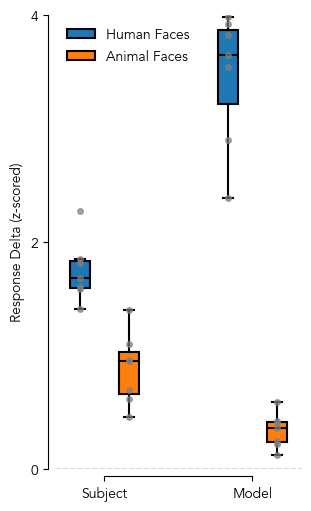

Plotting PPA...
Delta: Without humans - With humans


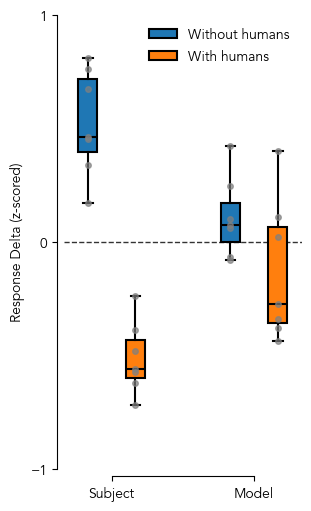

Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


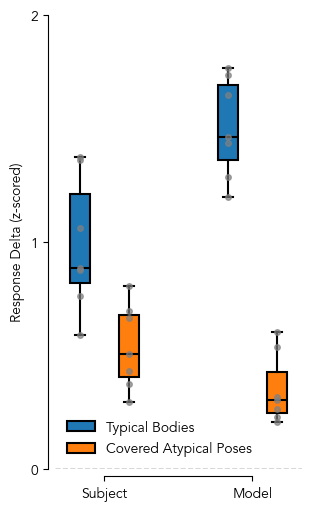

In [107]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [-1, 1],
    'EBA': [0, 2],
}
froi_ticks = {
    'FFA': np.array([0, 2, 4]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([0, 1, 2]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')
    # for model_name in TOP_MODEL_NAMES:
    df = []
    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]
    bag1_subject_responses_medians = []
    bag1_subject_responses_sems = []
    bag2_subject_responses_medians = []
    bag2_subject_responses_sems = []
    bag1_model_responses_medians = []
    bag1_model_responses_sems = []
    bag2_model_responses_medians = []
    bag2_model_responses_sems = []
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        bag1_subject_responses_medians.append(np.median(subject_responses_bag1))
        bag1_subject_responses_sems.append(sem(subject_responses_bag1))
        for pt in subject_responses_bag1:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        bag2_subject_responses_medians.append(np.median(subject_responses_bag2))
        bag2_subject_responses_sems.append(sem(subject_responses_bag2))
        for pt in subject_responses_bag2:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # subject_point_sem = median_diff_bootstrap(
        #     np.array(subject_responses_bag1_),
        #     np.array(subject_responses_bag2_),
        # )['sem']
        # subjects_response_deltas_median.append(np.median(subject_responses_bag1) - np.median(subject_responses_bag2))
        # subjects_response_deltas_sem.append(subject_point_sem)
        model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ][f'{model_name}_response']
        bag1_model_responses_medians.append(np.median(model_responses_bag1))
        bag1_model_responses_sems.append(sem(model_responses_bag1))
        for pt in model_responses_bag1:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ][f'{model_name}_response']
        bag2_model_responses_medians.append(np.median(model_responses_bag2))
        bag2_model_responses_sems.append(sem(model_responses_bag2))
        for pt in model_responses_bag2:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # model_response_deltas_median.append(np.median(model_responses_bag1) - np.median(model_responses_bag2))
        # model_point_sem = median_diff_bootstrap(
        #     np.array(model_responses_bag1),
        #     np.array(model_responses_bag2),
        # )['sem']
        # model_response_deltas_sem.append(model_point_sem)
    df = pd.DataFrame(df)
    if execute_lmm:
        run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    x_positions = [0, 1, 3, 4]

    # Plot a boxplot of medians for subjects and model for bag1 and bag2
    subject_data = [bag1_subject_responses_medians, bag2_subject_responses_medians]
    model_data = [bag1_model_responses_medians, bag2_model_responses_medians]
    box_colors = [bag1_color, bag2_color]
    box_labels = [bags[subjects[0]][bag_type]['bag1']['label'], bags[subjects[0]][bag_type]['bag2']['label']]
    box = ax.boxplot(
        subject_data + model_data,
        positions=x_positions,
        widths=0.4,
        patch_artist=True,
        medianprops=dict(color='black', linewidth=1.5),
        boxprops=dict(linewidth=1.5),
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5),
        flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    )
    for i, patch in enumerate(box['boxes']):
        color = box_colors[i % 2]
        patch.set_facecolor(color)
    
    # Add individual data points with SEM error bars
    for i, y in enumerate(subject_data + model_data):
        # x = np.random.normal(x_positions[i], 0.05, size=len(y))  # Add some jitter to the x-axis
        x = np.full_like(y, x_positions[i])  # No jitter
        ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=4, capsize=0)

    # Plot a boxplot of the response deltas, subjects and model
    # box_data = [subjects_response_deltas_median, model_response_deltas_median]
    # box_colors = [subject_color, model_color]
    # box_labels = ['Subject', 'Model']
    # box = ax.boxplot(
    #     box_data,
    #     positions=[0, 1],
    #     widths=0.4,
    #     patch_artist=True,
    #     medianprops=dict(color='black', linewidth=1.5),
    #     boxprops=dict(linewidth=1.5),
    #     whiskerprops=dict(linewidth=1.5),
    #     capprops=dict(linewidth=1.5),
    #     flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    # )
    # for patch, color in zip(box['boxes'], box_colors):
    #     patch.set_facecolor(color)

    # # Add individual data points with SEM error bars
    # # for i, (y, sem) in enumerate(zip(box_data, [subjects_response_deltas_sem, model_response_deltas_sem])):
    # #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    # #     ax.errorbar(x, y, yerr=sem, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)
    # for i, y in enumerate(box_data):
    #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    #     ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)

    ax.legend(
        [
            box["boxes"][0],
            box["boxes"][1],
        ],
        box_labels,
        loc='best',
        fontsize=10,
        frameon=False,
    )
    ax.set_xticks([0.5, 3.5])
    ax.set_xticklabels(['Subject', 'Model'], fontsize=12)
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)

    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_resnet50imagenet_bags_responses.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## d, g, j: Held-out subjects vs. Held-out top models

Plotting FFA...
Delta: Human Faces - Animal Faces


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_FFA_bags_faces.txt


...

Results written to: results/fig6_stats/possible_update_nsamples25/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_FFA_bags_faces.txt


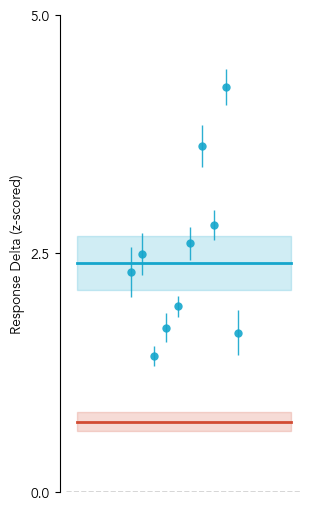

Plotting PPA...
Delta: Without humans - With humans


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_l

Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt
Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt
Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt
Results written to: results/fig6_stats/possible_update_nsamples25/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


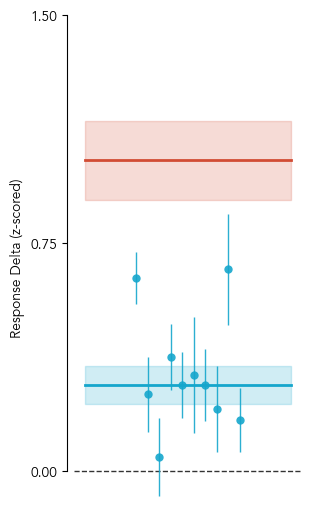

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/possible_update_nsamples25/lmm_EBA_bags_bodies.txt
Results written to: results/fig6_stats/possible_update_nsamples25/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


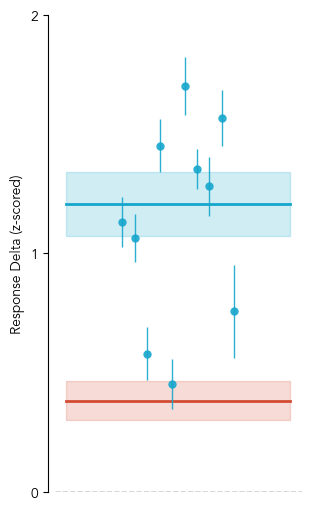

In [110]:
savefig = False
execute_lmm = True

froi_lims = {
    'FFA': [0, 5],
    'PPA': [-0.1, 1.5],
    'EBA': [0, 2],
}
froi_ticks = {
    'FFA': np.array([0, 2.5, 5]),
    'PPA': np.array([0, 0.75, 1.5]),
    'EBA': np.array([0, 1, 2]),
}

subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

subjects_color = '#d24c34'  # Red
models_color = '#15a6cc'    # Cyan

# for each froi
for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    # Subjects
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        subject_bags_median_responses.append([np.median(subject_responses_bag1), np.median(subject_responses_bag2)])
    subject_bags_median_responses = np.array(subject_bags_median_responses)

    # Models
    for model_name in TOP_MODEL_NAMES:
        # Skip resnet50imagenet1kv2 as it's the main model being compared
        if model_name == 'resnet50imagenet1kv2':
            continue
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    jitter_scale = 0.8

    # Draw a shaded area for subject delta ± SEM
    subjects_sem = sem(subject_bags_median_responses[:,0] - subject_bags_median_responses[:,1])
    subjects_median = np.median(subject_bags_median_responses[:,0]) - np.median(subject_bags_median_responses[:,1])
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=subjects_median - subjects_sem,
        y2=subjects_median + subjects_sem,
        color=subjects_color,
        alpha=0.2,
        # label='Subject Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [subjects_median, subjects_median],
        color=subjects_color,
        linestyle='-',
        linewidth=2,
        # label='Subject Δ',
    )

    # Collect all model median deltas for plotting later
    all_models_median_deltas = []
    # For each model, plot a point with error bars
    x_jitter = np.linspace(-(jitter_scale/2), jitter_scale/2, len(models_bags_median_responses))
    for model_idx, (model_name, model_bags_median_responses) in enumerate(models_bags_median_responses.items()):
        model_sem = sem(model_bags_median_responses[:,0] - model_bags_median_responses[:,1])
        model_median = np.median(model_bags_median_responses[:,0]) - np.median(model_bags_median_responses[:,1])
        all_models_median_deltas.append(model_median)
        # Plot error bar
        ax.errorbar(
            x=x_jitter[model_idx],
            y=model_median,
            yerr=model_sem,
            fmt='o',
            color=models_color,
            markeredgewidth=0,
            ecolor=models_color,
            elinewidth=1,
            capsize=0,
            markersize=6,
            alpha=0.9,
        )
        # Plot point
        # ax.plot(
        #     0,
        #     model_median,
        #     'o',
        #     color=models_color,
        #     markersize=8,
        #     alpha=0.9,
        #     label=f'{model_name} Δ',
        # )
    
    collated_models_median = np.median(all_models_median_deltas)
    collated_models_sem = sem(all_models_median_deltas)
    # Draw a shaded area for all models delta ± SEM
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=collated_models_median - collated_models_sem,
        y2=collated_models_median + collated_models_sem,
        color=models_color,
        alpha=0.2,
        # label='Model Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [collated_models_median, collated_models_median],
        color=models_color,
        linestyle='-',
        linewidth=2,
        # label='Model Δ',
    )

    # ax.legend(
    #     [
    #         box["boxes"][0],
    #         box["boxes"][1],
    #     ],
    #     box_labels,
    #     loc='best',
    #     fontsize=10,
    #     frameon=False,
    # )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)
    ax.get_xaxis().set_visible(False)


    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_heldoutmodels_bags_deltas.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## d, g, j: Control

Plotting FFA...
Delta: Human Faces - Animal Faces


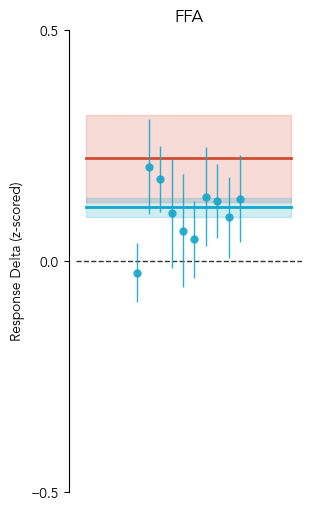

Plotting PPA...
Delta: Without humans - With humans


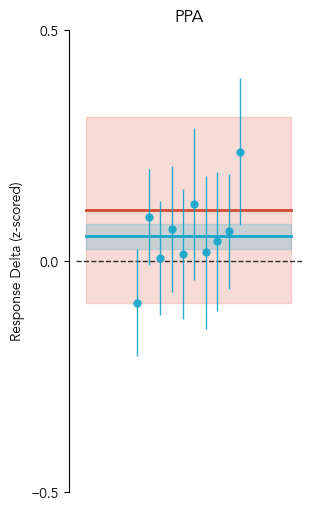

Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses


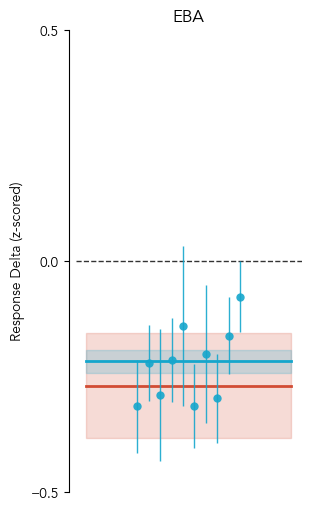

In [104]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [-0.5, 0.5],
    'PPA': [-0.5, 0.5],
    'EBA': [-0.5, 0.5],
}
froi_ticks = {
    'FFA': np.array([-0.5, 0, 0.5]),
    'PPA': np.array([-0.5, 0, 0.5]),
    'EBA': np.array([-0.5, 0, 0.5]),
}

subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

subjects_color = '#d24c34'  # Red
models_color = '#15a6cc'    # Cyan

# for each froi
for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    randomly_selected_nsdids = {}

    # Subjects
    for subject in subjects:
        subject_bags = bags[subject]
        subject_selected_nsdids = []
        for bag_type in subject_bags:
            subject_selected_nsdids += (subject_bags[bag_type]['bag1']['nsdids'] + subject_bags[bag_type]['bag2']['nsdids'])
        selected_nsdids = [nsdids_ for bag in bags[subject][bag_type].values() for nsdids_ in bag['nsdids']]
        original_bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        original_bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        # Randomly select new bag nsdids from the subject's available nsdids,
        bag1_nstim = len(original_bag1_nsdids)
        bag2_nstim = len(original_bag2_nsdids)
        subject_all_nsdids = set(resp_df[(resp_df['subject'] == subject)]['nsd_id'].unique())
        subject_candidate_nsdids = list(subject_all_nsdids - set(subject_selected_nsdids))
        # np.random.seed(42)
        bag1_nsdids = np.random.choice(subject_candidate_nsdids, size=bag1_nstim, replace=False).tolist()
        remaining_candidate_nsdids = list(set(subject_candidate_nsdids) - set(bag1_nsdids))
        bag2_nsdids = np.random.choice(remaining_candidate_nsdids, size=bag2_nstim, replace=False).tolist()
        # if subject == subjects[0]:
        #     print(f'Subject {subject} random bag nsdids:')
        #     print(f'  Original Bag1 ({bags[subject][bag_type]["bag1"]["label"]}): {sorted(original_bag1_nsdids)}')
        #     print(f'  Bag1 ({bags[subject][bag_type]["bag1"]["label"]}): {sorted(bag1_nsdids)}')
        #     print(f'  Original Bag2 ({bags[subject][bag_type]["bag2"]["label"]}): {sorted(original_bag2_nsdids)}')
        #     print(f'  Bag2 ({bags[subject][bag_type]["bag2"]["label"]}): {sorted(bag2_nsdids)}')
        randomly_selected_nsdids[subject] = {
            'bag1': bag1_nsdids,
            'bag2': bag2_nsdids,
        }
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        subject_bags_median_responses.append([np.median(subject_responses_bag1), np.median(subject_responses_bag2)])
    subject_bags_median_responses = np.array(subject_bags_median_responses)

    # Models
    for model_name in TOP_MODEL_NAMES:
        # Skip resnet50imagenet1kv2 as it's the main model being compared
        if model_name == 'resnet50imagenet1kv2':
            continue
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = randomly_selected_nsdids[subject]['bag1']
            bag2_nsdids = randomly_selected_nsdids[subject]['bag2']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
    df = pd.DataFrame(df)
    if execute_lmm:
        run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    jitter_scale = 0.8

    # Draw a shaded area for subject delta ± SEM
    subjects_sem = sem(subject_bags_median_responses[:,0] - subject_bags_median_responses[:,1])
    subjects_median = np.median(subject_bags_median_responses[:,0]) - np.median(subject_bags_median_responses[:,1])
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=subjects_median - subjects_sem,
        y2=subjects_median + subjects_sem,
        color=subjects_color,
        alpha=0.2,
        # label='Subject Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [subjects_median, subjects_median],
        color=subjects_color,
        linestyle='-',
        linewidth=2,
        # label='Subject Δ',
    )

    # Collect all model median deltas for plotting later
    all_models_median_deltas = []
    # For each model, plot a point with error bars
    x_jitter = np.linspace(-(jitter_scale/2), jitter_scale/2, len(models_bags_median_responses))
    for model_idx, (model_name, model_bags_median_responses) in enumerate(models_bags_median_responses.items()):
        model_sem = sem(model_bags_median_responses[:,0] - model_bags_median_responses[:,1])
        model_median = np.median(model_bags_median_responses[:,0]) - np.median(model_bags_median_responses[:,1])
        all_models_median_deltas.append(model_median)
        # Plot error bar
        ax.errorbar(
            x=x_jitter[model_idx],
            y=model_median,
            yerr=model_sem,
            fmt='o',
            color=models_color,
            markeredgewidth=0,
            ecolor=models_color,
            elinewidth=1,
            capsize=0,
            markersize=6,
            alpha=0.9,
        )
        # Plot point
        # ax.plot(
        #     0,
        #     model_median,
        #     'o',
        #     color=models_color,
        #     markersize=8,
        #     alpha=0.9,
        #     label=f'{model_name} Δ',
        # )
    
    collated_models_median = np.median(all_models_median_deltas)
    collated_models_sem = sem(all_models_median_deltas)
    # Draw a shaded area for all models delta ± SEM
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=collated_models_median - collated_models_sem,
        y2=collated_models_median + collated_models_sem,
        color=models_color,
        alpha=0.2,
        # label='Model Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [collated_models_median, collated_models_median],
        color=models_color,
        linestyle='-',
        linewidth=2,
        # label='Model Δ',
    )

    # ax.legend(
    #     [
    #         box["boxes"][0],
    #         box["boxes"][1],
    #     ],
    #     box_labels,
    #     loc='best',
    #     fontsize=10,
    #     frameon=False,
    # )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)
    ax.get_xaxis().set_visible(False)
    # Title
    ax.set_title(froi)


    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/{froi}_subject2to8_heldoutmodels_bags_deltas.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## b, c, d: Old

In [5]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

results_dir = f'{RESULTS_DIR}/fig6_stats'
os.makedirs(results_dir, exist_ok=True)

Plotting FFA...
Delta: Human Faces - Animal Faces
Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


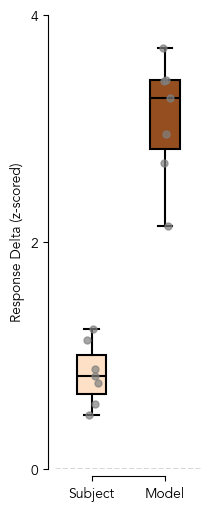

Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


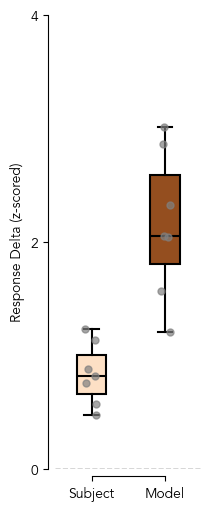

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


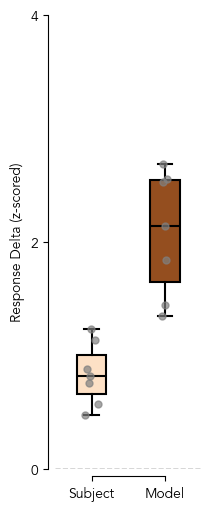

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


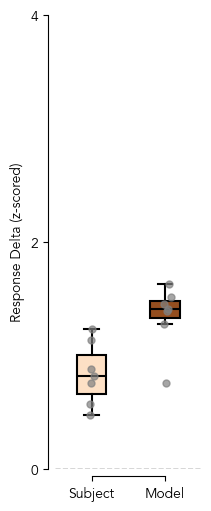

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


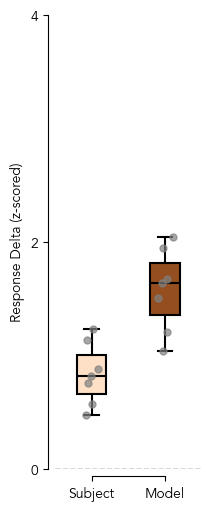

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


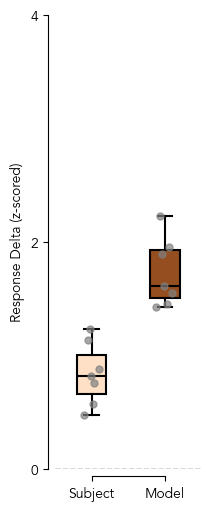

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


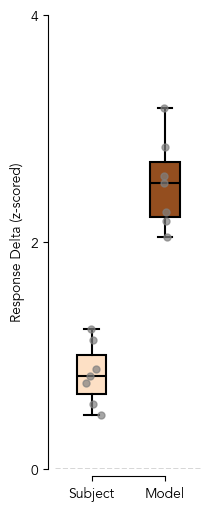

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


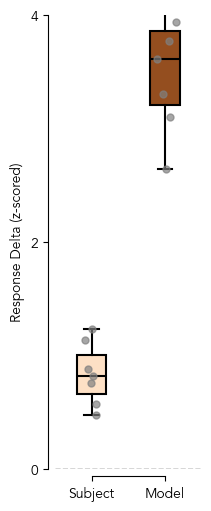

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


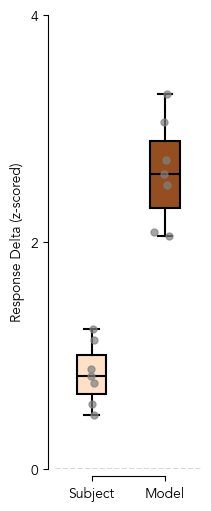

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


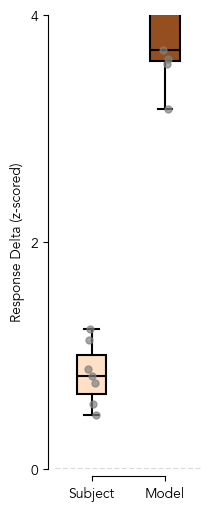

Results written to: results/fig6_stats/lmm_FFA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


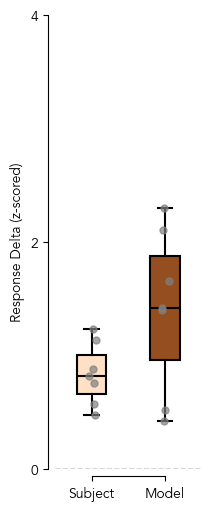

Plotting PPA...
Delta: Without humans - With humans
Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


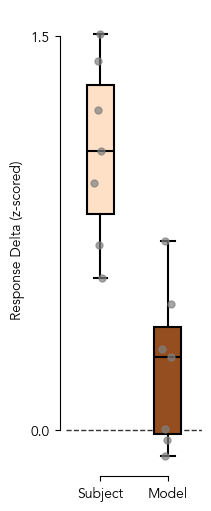

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


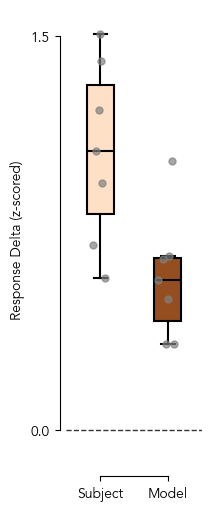

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


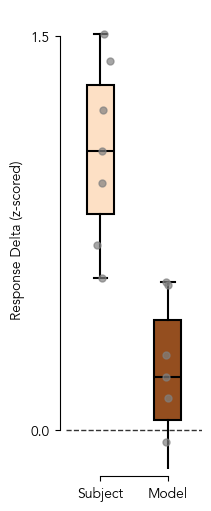

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


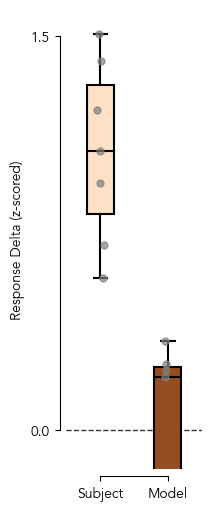

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


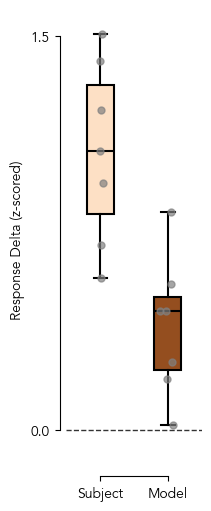

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


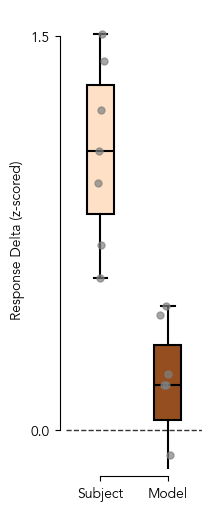

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


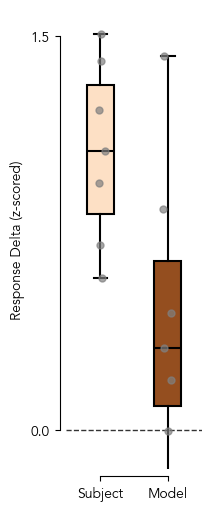

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


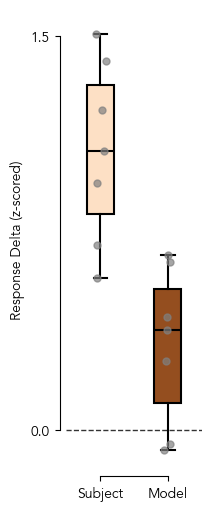

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


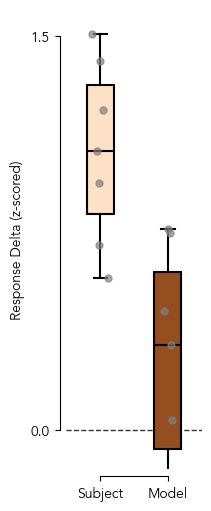

Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


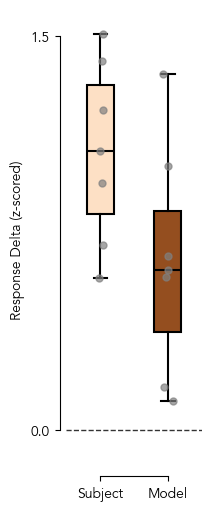

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_PPA_bags_scenes.txt


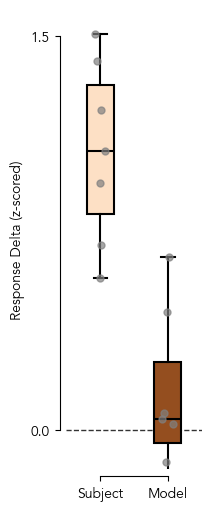

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Plotting EBA...
Delta: Typical Bodies - Covered Atypical Poses
Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


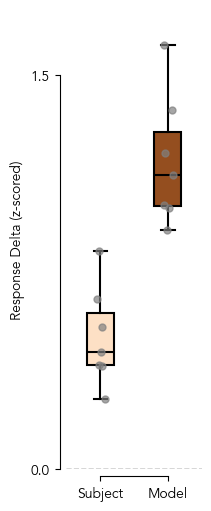

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


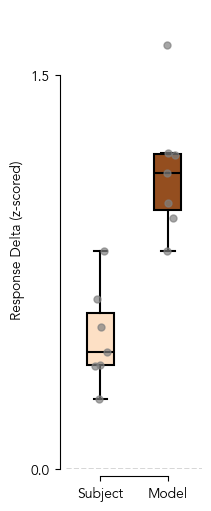

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


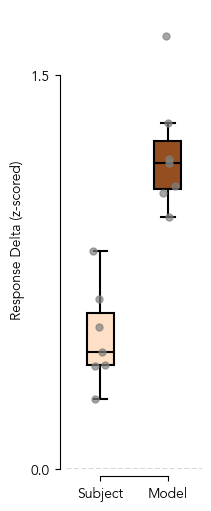

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


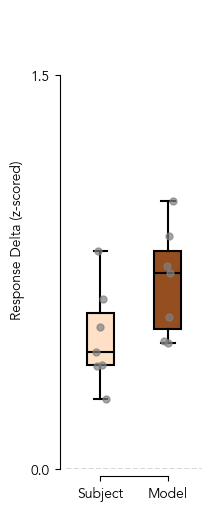

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


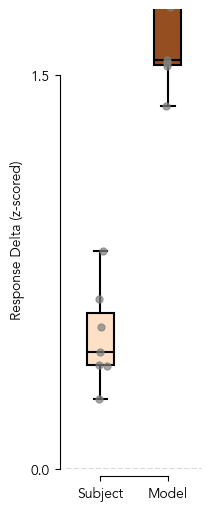

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


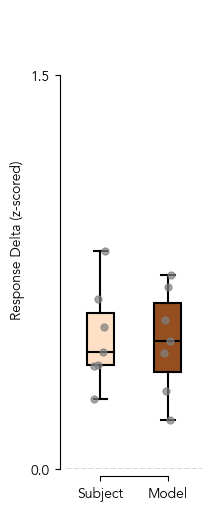

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


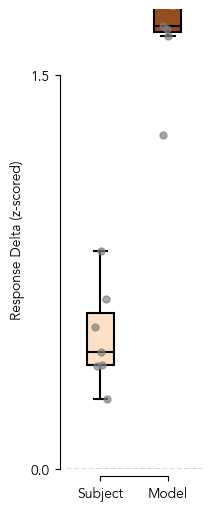

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


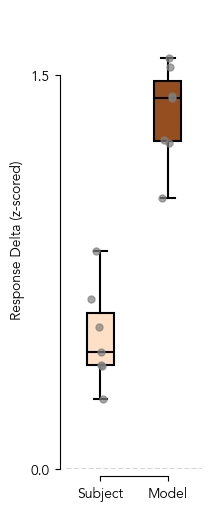

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


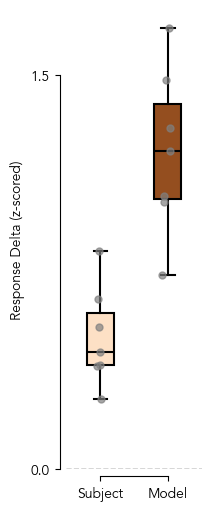

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


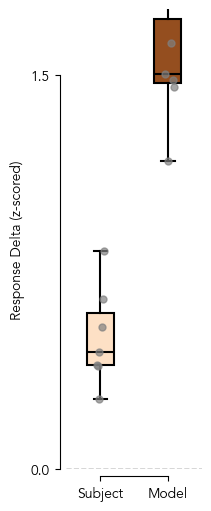

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/lmm_EBA_bags_bodies.txt


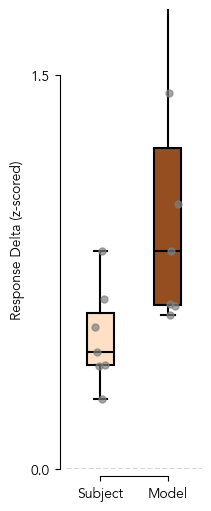

In [ ]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [-0.15, 1.6],
    'EBA': [0, 1.75],
}
froi_ticks = {
    'FFA': np.array([0, 2, 4]),
    'PPA': np.array([0, 1.5]),
    'EBA': np.array([0, 1.5]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags[subjects[0]][bag_type]["bag1"]["label"]} - {bags[subjects[0]][bag_type]["bag2"]["label"]}')
    for model_name in TOP_MODEL_NAMES:
        df = []
        fig, axes = plt.subplots(1, 1, figsize=(2, 5), constrained_layout=True)
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        model_response_deltas_median = []
        # model_response_deltas_sem = []
        subjects_response_deltas_median = []
        # subjects_response_deltas_sem = []

        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1_:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2_:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            # subject_point_sem = median_diff_bootstrap(
            #     np.array(subject_responses_bag1_),
            #     np.array(subject_responses_bag2_),
            # )['sem']
            subjects_response_deltas_median.append(np.median(subject_responses_bag1_) - np.median(subject_responses_bag2_))
            # subjects_response_deltas_sem.append(subject_point_sem)
            model_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1_:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2_:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_response_deltas_median.append(np.median(model_responses_bag1_) - np.median(model_responses_bag2_))
            # model_point_sem = median_diff_bootstrap(
            #     np.array(model_responses_bag1_),
            #     np.array(model_responses_bag2_),
            # )['sem']
            # model_response_deltas_sem.append(model_point_sem)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
        
        # Stats: Wilcoxon signed-rank test
        # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
        # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
        # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

        ax = axes
        # Add a horizontal line at y=0
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)

        # Plot a boxplot of the response deltas, subjects and model
        box_data = [subjects_response_deltas_median, model_response_deltas_median]
        box_colors = [subject_color, model_color]
        box_labels = ['Subject', 'Model']
        box = ax.boxplot(
            box_data,
            positions=[0, 1],
            widths=0.4,
            patch_artist=True,
            medianprops=dict(color='black', linewidth=1.5),
            boxprops=dict(linewidth=1.5),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5),
            flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
        )
        for patch, color in zip(box['boxes'], box_colors):
            patch.set_facecolor(color)

        # Add individual data points with SEM error bars
        # for i, (y, sem) in enumerate(zip(box_data, [subjects_response_deltas_sem, model_response_deltas_sem])):
        #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
        #     ax.errorbar(x, y, yerr=sem, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)
        for i, y in enumerate(box_data):
            x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
            ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)

        ax.set_xticks([0, 1])
        ax.set_xticklabels(box_labels)
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        ax.set_ylabel('Response Delta (z-scored)')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)

        # plt.tight_layout()
        if savefig:
            plt.savefig(f'{PLOTS_DIR}/fig6_lineplot_{froi}_{model_name}.pdf', dpi=300, bbox_inches='tight')
        else:
            plt.show()
        plt.close()

In [132]:
df

,response,system,condition,subject
0,3.187766,subject,Human Faces,2
1,2.055034,subject,Human Faces,2
2,2.180250,subject,Human Faces,2
3,2.436995,subject,Human Faces,2
4,3.104335,subject,Human Faces,2
...,...,...,...,...
819,0.323458,{resnet50imagenet1kv2},Animal Faces,8
820,0.224001,{resnet50imagenet1kv2},Animal Faces,8
821,0.093008,{resnet50imagenet1kv2},Animal Faces,8
822,0.096480,{resnet50imagenet1kv2},Animal Faces,8


In [99]:
import statsmodels.formula.api as smf

# Ensure categorical dtype (important!)
df["system"] = df["system"].astype("category")
df["condition"] = df["condition"].astype("category")


model = smf.mixedlm("response ~ condition * system", 
                    data=df, 
                    groups="subject", 
                    re_formula="~1")
result = model.fit()
print("Random intercept var:", float(result.cov_re.iloc[0,0]))
print("Baseline system:", df["system"].cat.categories[0])
print("Baseline condition:", df["condition"].cat.categories[0])
print(result.summary())

Random intercept var: 0.006268577013459822
Baseline system: model
Baseline condition: Covered Atypical Poses
                         Mixed Linear Model Regression Results
Model:                        MixedLM           Dependent Variable:           response  
No. Observations:             844               Method:                       REML      
No. Groups:                   7                 Scale:                        0.6409    
Min. group size:              112               Log-Likelihood:               -1018.1094
Max. group size:              128               Converged:                    Yes       
Mean group size:              120.6                                                     
----------------------------------------------------------------------------------------
                                              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------------------
Intercept                  

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [100]:
import numpy as np
import pandas as pd
from scipy.stats import norm

import statsmodels.formula.api as smf

# Ensure categorical dtype (important!)
df["system"] = df["system"].astype("category")
df["condition"] = df["condition"].astype("category")


model = smf.mixedlm("response ~ condition * system", 
                    data=df, 
                    groups="subject", 
                    re_formula="~1")
result = model.fit()
print("Random intercept var:", float(result.cov_re.iloc[0,0]))
print("Baseline system:", df["system"].cat.categories[0])
print("Baseline condition:", df["condition"].cat.categories[0])
print(result.summary())

# --- Identify parameter names programmatically ---
# Assumes 2 levels for condition and 2 for system (your case).
cond_levels = list(df["condition"].cat.categories)
sys_levels  = list(df["system"].cat.categories)
cond_base, cond_other = cond_levels[0], cond_levels[1]
sys_base,  sys_other  = sys_levels[0],  sys_levels[1]

# Build the exact coefficient labels that statsmodels used
b_intercept = "Intercept"
b_cond = f"condition[T.{cond_other}]"
b_sys  = f"system[T.{sys_other}]"
b_int  = f"{b_cond}:{b_sys}"

params = result.params
cov    = result.cov_params()

def lincomb(weights: dict[str, float]):
    """
    Linearly combine named coefficients with given weights and
    return estimate, SE, z, p, and 95% CI.
    """
    # Build full weight vector aligned with params index
    w = np.zeros(len(params))
    for name, val in weights.items():
        if name not in params.index:
            raise KeyError(f"Coefficient '{name}' not found in model params: {list(params.index)}")
        w[params.index.get_loc(name)] = val
    est = float(np.dot(w, params.values))
    se  = float(np.sqrt(w @ cov.values @ w))
    z   = est / se if se > 0 else np.nan
    p   = 2 * norm.sf(abs(z)) if se > 0 else np.nan
    ci_lo = est - 1.96 * se
    ci_hi = est + 1.96 * se
    return est, se, z, p, ci_lo, ci_hi

# --- Simple effects ---

# 1) System difference within each condition
#    (subject - model) at baseline condition
est1 = lincomb({b_sys: 1.0})
#    (subject - model) at the other condition
est2 = lincomb({b_sys: 1.0, b_int: 1.0})

# 2) Condition difference within each system
#    (other - baseline) for the model
est3 = lincomb({b_cond: 1.0})
#    (other - baseline) for the subject
est4 = lincomb({b_cond: 1.0, b_int: 1.0})

rows = [
    (f"System diff @ {cond_base}  ({sys_other} - {sys_base})",) + est1,
    (f"System diff @ {cond_other} ({sys_other} - {sys_base})",) + est2,
    (f"Condition diff @ {sys_base}  ({cond_other} - {cond_base})",) + est3,
    (f"Condition diff @ {sys_other} ({cond_other} - {cond_base})",) + est4,
]

simple_effects = pd.DataFrame(
    rows,
    columns=["Effect", "Estimate", "SE", "z", "p", "CI_low", "CI_high"]
)

print("\n=== Baselines ===")
print("Baseline system   :", sys_base)
print("Baseline condition:", cond_base)

print("\n=== Simple-effects tests ===")
print(simple_effects.round(4).to_string(index=False))

Random intercept var: 0.006268577013459822
Baseline system: model
Baseline condition: Covered Atypical Poses
                         Mixed Linear Model Regression Results
Model:                        MixedLM           Dependent Variable:           response  
No. Observations:             844               Method:                       REML      
No. Groups:                   7                 Scale:                        0.6409    
Min. group size:              112               Log-Likelihood:               -1018.1094
Max. group size:              128               Converged:                    Yes       
Mean group size:              120.6                                                     
----------------------------------------------------------------------------------------
                                              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------------------
Intercept                  

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [73]:
subjects_response_deltas_median

[np.float64(0.83126758),
 np.float64(0.398101235),
 np.float64(0.26611458500000007),
 np.float64(0.5405151300000001),
 np.float64(0.6475803699999999),
 np.float64(0.4475062000000001),
 np.float64(0.39443955500000005)]

In [74]:
model_response_deltas_median

[np.float64(1.3653865600000001),
 np.float64(1.118023495),
 np.float64(1.00442996),
 np.float64(1.2038149000000002),
 np.float64(1.61503686),
 np.float64(0.90873823),
 np.float64(0.99606031)]

In [78]:
d = np.array(subjects_response_deltas_median) - np.array(model_response_deltas_median)
wilcoxon_stat, p_wil = wilcoxon(d, alternative='two-sided')
print(f'Overall Wilcoxon signed-rank test: statistic={wilcoxon_stat}, p-value={p_wil}')

Overall Wilcoxon signed-rank test: statistic=0.0, p-value=0.015625


In [79]:
# Paired permutation (label swap within set)
rng = np.random.default_rng(42)
B = 100000
obs = d.mean()
null = np.empty(B)
for b in range(B):
    flips = rng.choice([1, -1], size=len(d))     # swap model/human within each set
    null[b] = (flips * d).mean()
p_perm = (np.abs(null) >= np.abs(obs)).mean()
print(f'Overall permutation test: statistic={obs}, p-value={p_perm}')

Overall permutation test: statistic=-0.6694236657142857, p-value=0.01595


In [69]:
median_diff_bootstrap(
    subject_responses_bag1_,
    subject_responses_bag2_,
    B=10
)['sem']

np.float64(0.15317515612106508)

# Fig 6 Supplementary: Failed hypotheses

In [ ]:
bags_failedhypotheses = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958,
                    7756, 9871, 9686, 10161, 13337,
                    14080, 14522, 15057, 15563, 16028,
                    16493, 17447, 18520, 20083, 20974,
                    22259, 24310, 26031, 26050, 26860,
                    # 27682, 27824, 30316, 30577, 33486
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363,
                    13578, 17070, 17146, 23628, 25482,
                    26640, 27637, 28387, 29961, 31413,
                    32166, 32837, 33769, 35316, 35352,
                    35641, 38705, 40208, 40908, 42107,
                    # 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 2473,
                    2943, 3928, 4155, 4741, 5005,
                    5082, 6837, 8749, 9417, 9429,
                    10376, 10963, 12343, 13469, 13867,
                    14798, 15663, 16602, 16504, 17312,
                    # 18455, 22161, 22481, 23007
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363,
                    13578, 17070, 17146, 23628, 25482,
                    26640, 27637, 28387, 29961, 31413,
                    32166, 32837, 33769, 35316, 35352,
                    35641, 38705, 40208, 40908, 42107,
                    # 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717,
                    15478, 16906, 17187, 17277, 17328, 18701, 24589, 24661, 26049, 28124,
                    29193, 31658, 32393, 32495, 35055,
                    # 35570, 37251, 37293, 38179, 39214, 41713, 41772
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1085, 1219, 1908, 5221,
                    5387, 7012, 11163, 11828, 13162, 13810, 15994,
                    17282, 17803, 19084, 21991, 31486, 32927,
                    37975, 39799, 42526, 43576, 44489, 44488, 45032,
                ],
            }
        },
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864,
                    6650, 7338, 10644, 13690, 13794,
                    13804, 16357, 17793, 21374, 22770,
                    25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230,
                    3101, 3218, 5662, 6931, 7702,
                    8060, 8099, 10439, 11138, 11152,
                    11284, 11401, 11739, 12124, 15305,
                    17931, 19948, 20000, 21837, 25688 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932,
                    6794, 7197, 7340, 7463, 7542,
                    7823, 9221, 9938, 11810, 12230,
                    12758, 16719, 18889, 21717, 23513,
                    27334, 28482, 29701, 32719, 37762,
                    # 43980
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230,
                    3101, 3218, 5662, 6931, 7702,
                    8060, 8099, 10439, 11138, 11152,
                    11284, 11401, 11739, 12124, 15305,
                    17931, 19948, 20000, 21837, 25688
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    11, 515, 1179, 1255, 2133,
                    2496, 2463, 3091, 3396, 3758,
                    5014, 7632, 8904, 8911, 9852,
                    11346, 12583, 12978, 13642, 15569,
                    22882, 64770, 63494, 62839, 54782,
                    # 54516, 47062
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1280, 2274, 2727, 3661, 4462,
                    7258, 8051, 8403, 9119, 11195,
                    12018, 12649, 14272, 14816, 17467,
                    17615, 18643, 20412, 22529, 27851,
                    31957, 32006, 32250, 32902, 34515
                ],
            }
        },
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810,
                    12511, 12985, 14579, 14678, 16902,
                    17882, 18217, 18628, 19100, 19205,
                    19625, 20360, 20399, 20821, 22308,
                    22681, 25571, 26563, 28966, 30379,
                    # 30749, 33122, 33329, 33477, 34482,
                    # 39638, 41000, 42905, 45061, 46327,
                    # 47383, 50935
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567,
                    14359, 17153, 17472, 19272, 19960,
                    20245, 20721, 21931, 22420, 24930,
                    30469, 31033, 31230, 34988, 34755,
                    35620, 35900, 36011, 37165, 37804,
                    # 37980, 38083, 40989, 41644, 41728,
                    # 43041, 43262, 43460, 43831, 45744,
                    # 46297,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    496, 648, 1451, 5824, 6204,
                    7327, 12416, 13193, 17023, 20544,
                    21753, 22071, 23747, 24853,  29147,
                    33771, 34465, 34639, 41941, 48570,
                    50251, 50333, 52416, 53600, 56260,
                    # 62583, 65991, 66086, 68223, 69065
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    44509, 51133, 54875, 8599, 9948,
                    14019, 15669, 17432, 22197, 24174,
                    26392, 27004, 30975, 34710, 35341,
                    38822, 39121, 39205, 42031, 48479,
                    42535, 43390, 44513, 46780, 47811,
                    # 71292, 69123, 68736, 65846, 11308,
                ],
            }
        },
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197, # 14421
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                      
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    7895, 457, 1434, 3737, 3456,
                    7895, 6397, 10124, 9873, 11701,
                    10826, 13159, 13695, 13441, 14750,
                    16988, 19081, 19819, 21302, 23911,
                    23430, 26046, 26071, 27123, 28499,
                    # 28261, 29875
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298,
                    5396, 5002, 7982, 11667, 69530,
                    10996, 14339, 14948, 14201, 15360,
                    18044, 22647, 24059, 27361, 26436, 
                    25752, 26356, 28784, 6993, 19739,
                ],
            }
        },
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841,
                    8588, 8830, 9295, 9442, 9475,
                    57999, 9676, 12326, 12904, 13979,
                    17687, 17817, 24280, 25419, 27289,
                    57915, 38680, 40104, 41422, 41930,
                    # 50862, 53385, 53428, 54805, 55168,
                    # 56232, 57797
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923,
                    4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740,
                    12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426,
                    # 26429, 33557, 37434, 37767, 38216,
                    # 39257
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    122, 834, 1017, 1688, 2167,
                    2380, 3065, 3447, 4733, 4780,
                    5570, 6556, 7794, 8376, 8943,
                    9784, 13350, 14341, 17723, 18788,
                    19616, 21804, 22436, 22814, 27213,
                    # 30586, 32312, 32318, 37415, 39580,
                    # 40071, 43962, 48780, 50196
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    18, 744, 1417, 3366, 5294,
                    6294, 8726, 9190, 9719, 11366,
                    13730, 15322, 16108, 17880, 17964,
                    18038, 19299, 22626, 23298, 25222,
                    25265, 28649, 28822, 30071, 34666,
                    # 35219, 37663, 39035, 40192, 40319,
                    # 41024, 41349
                ],
            }
        },
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512,
                    14054, 14073, 14322, 14546, 16064,
                    16695, 18093, 18196, 19512, 20785,
                    22694, 25383, 25621, 28236, 30227,
                    31194, 32037, 32586, 32925, 33216,
                    # 33356, 33383, 33959, 34216, 34375,
                    # 34636, 34694, 35990, 36642, 36657,
                    # 38014, 38348, 39015, 39607, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497,
                    5573, 5894, 7165, 7386, 7474,
                    8508, 10081, 10944, 11047, 12603, 
                    14759, 15422, 15597, 16164, 16871,
                    16874, 16943, 19590, 20048, 20891,
                    # 21028, 21213, 21207, 21402, 22399,
                    # 22582, 22641, 23268, 25240, 26781, 
                    # 28034, 28223, 28483, 29855, 29856,
                    # 31011, 34170, 44771,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    461, 2629, 7124, 8686, 10362,
                    12427, 15183, 19881, 22977, 26072,
                    27247, 28873, 30335, 30755, 32002,
                    32292, 33724, 35267, 38654, 41500,
                    43609, 72949, 60287, 53162, 49803,
                    # 46956, 44771, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    449, 810, 1703, 3087, 4856,
                    5816, 7900, 71794, 71755, 69927,
                    10658, 15020, 15147, 15511, 16641,
                    17160, 19019, 19861, 20526, 21161,
                    36860, 41940, 42283, 42264, 71947, 
                    # 59262, 
                ],
            }
        },
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151,
                    5531, 7579, 7677, 8270, 8841,
                    9635, 9776, 10367, 13490, 16118,
                    17641, 17730, 18861, 19641, 20340,
                    20982, 21532, 21761, 22178, 25648,
                    # 25976, 44902,  
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360,
                    1665, 1868, 2916, 3487, 4272,
                    4382, 5407, 7734, 8446, 9308,
                    9501, 10720, 11979, 11995, 12400,
                    12369, 13436, 13473, 13797, 14348, 
                    # 14418, 16869, 17414,  
                ],
            }
        },
        'scenes': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    1648, 2027, 6356, 9049, 13323,
                    21380, 23665, 26449, 27955, 29716,
                    29823, 30180, 43607, 44187, 45758,
                    49150, 50578, 55934, 56320, 56467,
                    60213, 72029, 70040, 69525, 67399,
                    # 66667, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091,
                    6683, 7161, 11028, 20509, 25734,
                    26992, 27998, 29483, 32165, 32297,
                    32256, 33490, 71445, 71307, 70549,
                    70088, 69931, 69583, 68038, 67986,
                    # 67178, 65969
                ],
            }
        },
    },
}

bag_nsamples_df = []

comparisons_considered = ['faces', 'bodies', 'scenes', 'animal_faces_bodies']
bags_considered = ['Human Faces', 'Human Bodies', 'Animal Faces', 'Animal Bodies', 'Vanishing Point', 'No Vanishing Point']

for subject in range(2, 9):
    sbj_row = {'subject': subject}
    sbj_bags = bags_failedhypotheses[subject]
    for comparison_type in sbj_bags:
        if comparison_type not in comparisons_considered:
            continue
        comparison = sbj_bags[comparison_type]
        for bag_key in list(comparison.keys()):
            bag = comparison[bag_key]
            if bag['label'] in bags_considered:
                sbj_row[bag['label']] = len(bag['nsdids'])
    bag_nsamples_df.append(sbj_row)
bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
display(bag_nsamples_df)

# Print total, mean and std per bag
for bag_label in bags_considered:
    total = bag_nsamples_df[bag_label].sum()
    mean = bag_nsamples_df[bag_label].mean()
    std = bag_nsamples_df[bag_label].std()
    print(f"{bag_label}: Total={total}, Mean={mean:.2f}, Std={std:.2f}")

,subject,Human Faces,Human Bodies,Animal Bodies,Animal Faces,Vanishing Point,No Vanishing Point
0,2,31,25,25,25.0,25,24
1,3,27,24,25,NaN,25,25
2,4,35,25,25,NaN,25,25
3,5,30,0,0,NaN,25,25
4,6,28,25,25,NaN,25,25
5,7,33,25,25,NaN,25,25
6,8,25,25,25,NaN,25,25


Human Faces: Total=209, Mean=29.86, Std=3.48
Human Bodies: Total=149, Mean=21.29, Std=9.39
Animal Faces: Total=25.0, Mean=25.00, Std=nan
Animal Bodies: Total=150, Mean=21.43, Std=9.45
Vanishing Point: Total=175, Mean=25.00, Std=0.00
No Vanishing Point: Total=174, Mean=24.86, Std=0.38


In [79]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

# frois = ['FFA', 'PPA', 'EBA']
frois = ['EBA']
subjects = [2, 3, 4, 6, 7, 8]  # NSD subjects # TODO: Add back 5 when possible
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'faces',
}
# model_color = '#944e1f' # Brown
# subject_color = '#fde0c5' # Light peach

bag1_color = '#1f77b4'  # Blue
bag2_color = '#ff7f0e'  # Orange

results_dir = f'{RESULTS_DIR}/fig6_stats/failed_hypotheses'
os.makedirs(results_dir, exist_ok=True)

plot_dir = f'{PLOTS_DIR}/individual_plots/failed_hypotheses'
os.makedirs(plot_dir, exist_ok=True)

hh_color = '#d24c34'
mh_color = '#15a6cc'

## Held-out subjects vs. ResNet-50 ImageNet1K

Plotting EBA...
Delta: Human Faces - Human Bodies


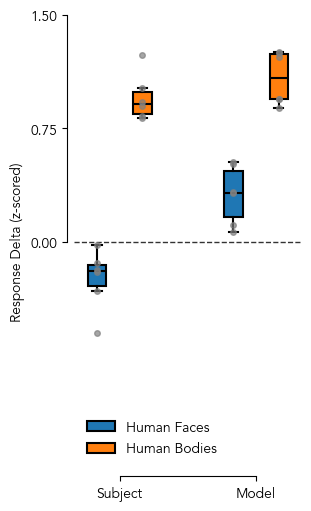

In [82]:
savefig = False
execute_lmm = False

froi_lims = {
    'FFA': [-1, 4],
    'PPA': [0, 2],
    'EBA': [-1.5, 1.5],
}
froi_ticks = {
    'FFA': np.array([0, 2, 4]),
    'PPA': np.array([0, 1, 2]),
    'EBA': np.array([0, 0.75, 1.5]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags_failedhypotheses[subjects[0]][bag_type]["bag1"]["label"]} - {bags_failedhypotheses[subjects[0]][bag_type]["bag2"]["label"]}')
    # for model_name in TOP_MODEL_NAMES:
    df = []
    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]
    bag1_subject_responses_medians = []
    bag1_subject_responses_sems = []
    bag2_subject_responses_medians = []
    bag2_subject_responses_sems = []
    bag1_model_responses_medians = []
    bag1_model_responses_sems = []
    bag2_model_responses_medians = []
    bag2_model_responses_sems = []
    for subject in subjects:
        bag1_nsdids = bags_failedhypotheses[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags_failedhypotheses[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        bag1_subject_responses_medians.append(np.median(subject_responses_bag1))
        bag1_subject_responses_sems.append(sem(subject_responses_bag1))
        for pt in subject_responses_bag1:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags_failedhypotheses[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        bag2_subject_responses_medians.append(np.median(subject_responses_bag2))
        bag2_subject_responses_sems.append(sem(subject_responses_bag2))
        for pt in subject_responses_bag2:
            df.append({
                'response': pt,
                'system': 'subject',
                'condition': bags_failedhypotheses[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # subject_point_sem = median_diff_bootstrap(
        #     np.array(subject_responses_bag1_),
        #     np.array(subject_responses_bag2_),
        # )['sem']
        # subjects_response_deltas_median.append(np.median(subject_responses_bag1) - np.median(subject_responses_bag2))
        # subjects_response_deltas_sem.append(subject_point_sem)
        model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ][f'{model_name}_response']
        bag1_model_responses_medians.append(np.median(model_responses_bag1))
        bag1_model_responses_sems.append(sem(model_responses_bag1))
        for pt in model_responses_bag1:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags_failedhypotheses[subject][bag_type]['bag1']['label'],
                'subject': subject,
            })
        model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ][f'{model_name}_response']
        bag2_model_responses_medians.append(np.median(model_responses_bag2))
        bag2_model_responses_sems.append(sem(model_responses_bag2))
        for pt in model_responses_bag2:
            df.append({
                'response': pt,
                'system': model_name,
                'condition': bags_failedhypotheses[subject][bag_type]['bag2']['label'],
                'subject': subject,
            })
        # model_response_deltas_median.append(np.median(model_responses_bag1) - np.median(model_responses_bag2))
        # model_point_sem = median_diff_bootstrap(
        #     np.array(model_responses_bag1),
        #     np.array(model_responses_bag2),
        # )['sem']
        # model_response_deltas_sem.append(model_point_sem)
    df = pd.DataFrame(df)
    if execute_lmm:
        run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    x_positions = [0, 1, 3, 4]

    # Plot a boxplot of medians for subjects and model for bag1 and bag2
    subject_data = [bag1_subject_responses_medians, bag2_subject_responses_medians]
    model_data = [bag1_model_responses_medians, bag2_model_responses_medians]
    box_colors = [bag1_color, bag2_color]
    box_labels = [bags_failedhypotheses[subjects[0]][bag_type]['bag1']['label'], bags_failedhypotheses[subjects[0]][bag_type]['bag2']['label']]
    box = ax.boxplot(
        subject_data + model_data,
        positions=x_positions,
        widths=0.4,
        patch_artist=True,
        medianprops=dict(color='black', linewidth=1.5),
        boxprops=dict(linewidth=1.5),
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5),
        flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    )
    for i, patch in enumerate(box['boxes']):
        color = box_colors[i % 2]
        patch.set_facecolor(color)
    
    # Add individual data points with SEM error bars
    for i, y in enumerate(subject_data + model_data):
        # x = np.random.normal(x_positions[i], 0.05, size=len(y))  # Add some jitter to the x-axis
        x = np.full_like(y, x_positions[i])  # No jitter
        ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=4, capsize=0)

    # Plot a boxplot of the response deltas, subjects and model
    # box_data = [subjects_response_deltas_median, model_response_deltas_median]
    # box_colors = [subject_color, model_color]
    # box_labels = ['Subject', 'Model']
    # box = ax.boxplot(
    #     box_data,
    #     positions=[0, 1],
    #     widths=0.4,
    #     patch_artist=True,
    #     medianprops=dict(color='black', linewidth=1.5),
    #     boxprops=dict(linewidth=1.5),
    #     whiskerprops=dict(linewidth=1.5),
    #     capprops=dict(linewidth=1.5),
    #     flierprops=dict(marker='o', color='gray', alpha=0.5, markersize=5, markeredgecolor='none')
    # )
    # for patch, color in zip(box['boxes'], box_colors):
    #     patch.set_facecolor(color)

    # # Add individual data points with SEM error bars
    # # for i, (y, sem) in enumerate(zip(box_data, [subjects_response_deltas_sem, model_response_deltas_sem])):
    # #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    # #     ax.errorbar(x, y, yerr=sem, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)
    # for i, y in enumerate(box_data):
    #     x = np.random.normal(i, 0.05, size=len(y))  # Add some jitter to the x-axis
    #     ax.errorbar(x, y, fmt='o', color='gray', alpha=0.7, markersize=5, capsize=0)

    ax.legend(
        [
            box["boxes"][0],
            box["boxes"][1],
        ],
        box_labels,
        loc='best',
        fontsize=10,
        frameon=False,
    )
    ax.set_xticks([0.5, 3.5])
    ax.set_xticklabels(['Subject', 'Model'], fontsize=12)
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)

    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/failedhypotheses_{froi}_subject2to8_resnet50imagenet_bags_responses.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## Held-out subjects vs. Held-out top models

Plotting EBA...
Delta: Human Faces - Human Bodies


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Results written to: results/fig6_stats/failed_hypotheses/lmm_EBA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


Results written to: results/fig6_stats/failed_hypotheses/lmm_EBA_bags_faces.txt


...

/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 10.551993
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning

Results written to: results/fig6_stats/failed_hypotheses/lmm_EBA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 7.872162
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)

Results written to: results/fig6_stats/failed_hypotheses/lmm_EBA_bags_faces.txt
Results written to: results/fig6_stats/failed_hypotheses/lmm_EBA_bags_faces.txt


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 9.540809
  warnings.warn(msg, ConvergenceWarning)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)

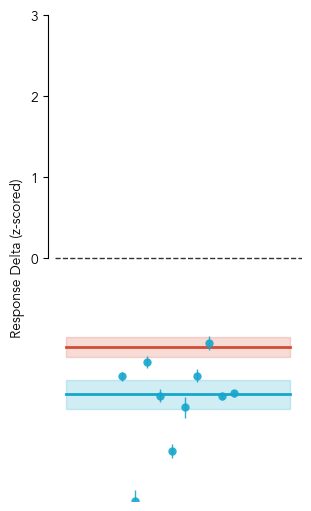

In [83]:
savefig = False
execute_lmm = True

froi_lims = {
    'FFA': [-5, 5],
    'PPA': [-0.5, 0.5],
    'EBA': [-3, 0],
}
froi_ticks = {
    'FFA': np.array([0, 2.5, 5]),
    'PPA': np.array([-0.5, 0, 0.5]),
    'EBA': np.array([0, 1, 2, 3]),
}

subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425

subjects_color = '#d24c34'  # Red
models_color = '#15a6cc'    # Cyan

# for each froi
for froi in frois:
    bag_type = froi_bags[froi]
    lmm_output_file_path = f'{results_dir}/lmm_{froi}_bags_{bag_type}.txt'
    print(f'Plotting {froi}...')
    print(f'Delta: {bags_failedhypotheses[subjects[0]][bag_type]["bag1"]["label"]} - {bags_failedhypotheses[subjects[0]][bag_type]["bag2"]["label"]}')

    # Variables for storing bag responses
    models_bags_median_responses = {}
    subject_bags_median_responses = []

    # Subjects
    for subject in subjects:
        bag1_nsdids = bags_failedhypotheses[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags_failedhypotheses[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
        ]['subject_response']
        subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
            sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
        ]['subject_response']
        subject_bags_median_responses.append([np.median(subject_responses_bag1), np.median(subject_responses_bag2)])
    subject_bags_median_responses = np.array(subject_bags_median_responses)

    # Models
    for model_name in TOP_MODEL_NAMES:
        # Skip resnet50imagenet1kv2 as it's the main model being compared
        if model_name == 'resnet50imagenet1kv2':
            continue
        model_bags_median_responses = []
        df = []
        for subject in subjects:
            bag1_nsdids = bags_failedhypotheses[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags_failedhypotheses[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag1:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags_failedhypotheses[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            subject_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            for pt in subject_responses_bag2:
                df.append({
                    'response': pt,
                    'system': 'subject',
                    'condition': bags_failedhypotheses[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_responses_bag1 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag1:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags_failedhypotheses[subject][bag_type]['bag1']['label'],
                    'subject': subject,
                })
            model_responses_bag2 = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            for pt in model_responses_bag2:
                df.append({
                    'response': pt,
                    'system': model_name,
                    'condition': bags_failedhypotheses[subject][bag_type]['bag2']['label'],
                    'subject': subject,
                })
            model_bags_median_responses.append([np.median(model_responses_bag1), np.median(model_responses_bag2)])
        models_bags_median_responses[model_name] = np.array(model_bags_median_responses)
        df = pd.DataFrame(df)
        if execute_lmm:
            run_lmm(df, lmm_output_file_path)
    
    # Stats: Wilcoxon signed-rank test
    # print(np.median(subjects_response_deltas_median), np.median(model_response_deltas_median))
    # stat, p_value = wilcoxon(subjects_response_deltas_median, model_response_deltas_median)
    # print(f'  Wilcoxon signed-rank test: statistic={stat}, p-value={p_value}')

    fig, axes = plt.subplots(1, 1, figsize=(3, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]

    ax = axes
    # Add a horizontal line at y=0
    ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
    jitter_scale = 0.8

    # Draw a shaded area for subject delta ± SEM
    subjects_sem = sem(subject_bags_median_responses[:,0] - subject_bags_median_responses[:,1])
    subjects_median = np.median(subject_bags_median_responses[:,0]) - np.median(subject_bags_median_responses[:,1])
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=subjects_median - subjects_sem,
        y2=subjects_median + subjects_sem,
        color=subjects_color,
        alpha=0.2,
        # label='Subject Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [subjects_median, subjects_median],
        color=subjects_color,
        linestyle='-',
        linewidth=2,
        # label='Subject Δ',
    )

    # Collect all model median deltas for plotting later
    all_models_median_deltas = []
    # For each model, plot a point with error bars
    x_jitter = np.linspace(-(jitter_scale/2), jitter_scale/2, len(models_bags_median_responses))
    for model_idx, (model_name, model_bags_median_responses) in enumerate(models_bags_median_responses.items()):
        model_sem = sem(model_bags_median_responses[:,0] - model_bags_median_responses[:,1])
        model_median = np.median(model_bags_median_responses[:,0]) - np.median(model_bags_median_responses[:,1])
        all_models_median_deltas.append(model_median)
        # Plot error bar
        ax.errorbar(
            x=x_jitter[model_idx],
            y=model_median,
            yerr=model_sem,
            fmt='o',
            color=models_color,
            markeredgewidth=0,
            ecolor=models_color,
            elinewidth=1,
            capsize=0,
            markersize=6,
            alpha=0.9,
        )
        # Plot point
        # ax.plot(
        #     0,
        #     model_median,
        #     'o',
        #     color=models_color,
        #     markersize=8,
        #     alpha=0.9,
        #     label=f'{model_name} Δ',
        # )
    
    collated_models_median = np.median(all_models_median_deltas)
    collated_models_sem = sem(all_models_median_deltas)
    # Draw a shaded area for all models delta ± SEM
    ax.fill_between(
        x=[-jitter_scale, jitter_scale],
        y1=collated_models_median - collated_models_sem,
        y2=collated_models_median + collated_models_sem,
        color=models_color,
        alpha=0.2,
        # label='Model Δ ± SEM',
    )
    # Draw a line for subject delta
    ax.plot(
        [-jitter_scale, jitter_scale],
        [collated_models_median, collated_models_median],
        color=models_color,
        linestyle='-',
        linewidth=2,
        # label='Model Δ',
    )

    # ax.legend(
    #     [
    #         box["boxes"][0],
    #         box["boxes"][1],
    #     ],
    #     box_labels,
    #     loc='best',
    #     fontsize=10,
    #     frameon=False,
    # )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylim(y_lims)
    ax.set_yticks(y_ticks)
    ax.set_ylabel('Response Delta (z-scored)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
    ax.spines['bottom'].set_bounds(0.5, 3.5)
    ax.get_xaxis().set_visible(False)


    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/failedhypotheses_{froi}_subject2to8_heldoutmodels_bags_deltas.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

# Fig 6: Old

## a, b, c

In [9]:
frois = ['FFA', 'PPA', 'EBA']
subject = 1
model_name = 'resnet50imagenet1kv2'

froi_515_df_dict = {}
for froi in frois:
    print(f"Loading data for {froi}...")
    froi_515_df_dict[froi], _, _, _, _ = get_data(
        subject, froi, subset=515, model_name=model_name
    )

Loading data for FFA...
loading annotations into memory...
Done (t=7.15s)
creating index...
index created!
loading annotations into memory...
Done (t=0.50s)
creating index...
index created!
loading annotations into memory...
Done (t=0.31s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6459, RDMR: 0.3385
Loading data for PPA...
loading annotations into memory...
Done (t=7.17s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6966, RDMR: 0.2800
Loading data for EBA...
loading annotations into memory...
Done (t=7.27s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index creat

FFA diffs min: 0.005176139064133167, max: 3.433906078338623
PPA diffs min: 0.001626485143788159, max: 1.967289686203003
EBA diffs min: 0.0002875679638236761, max: 2.0667526721954346


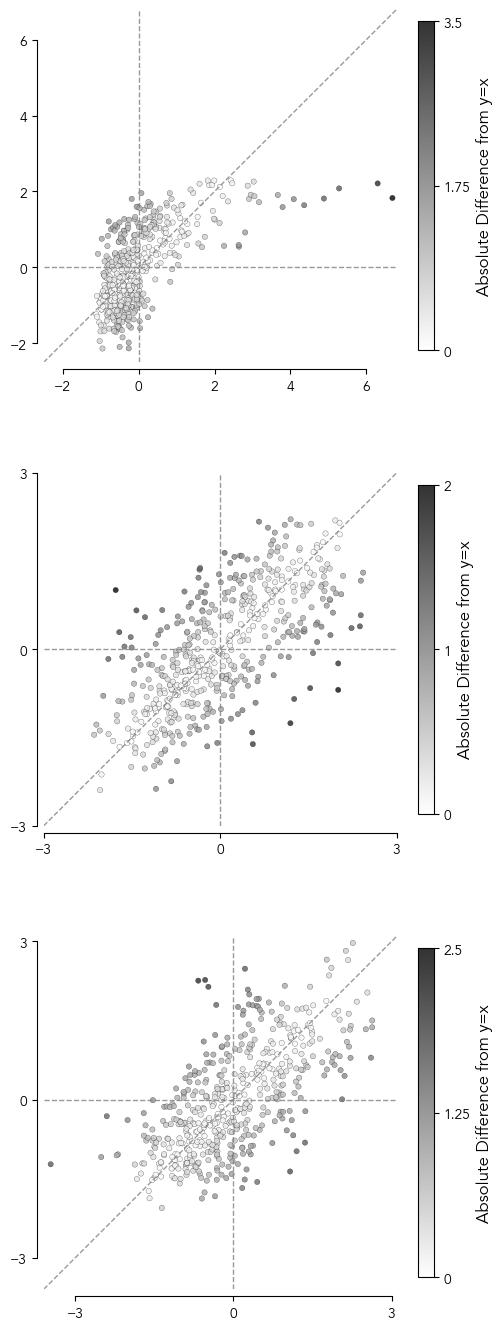

In [69]:
froi_lims = {
    'FFA': [-2.5, 6.8],
    'PPA': [-3, 3],
    'EBA': [-3.6, 3.1],
}
froi_ticks = {
    'FFA': np.array([-2, 0, 2, 4, 6]),
    'PPA': np.array([-3, 0, 3]),
    'EBA': np.array([-3, 0, 3]),
}

fig, ax = plt.subplots(3, 1, figsize=(5, 14), constrained_layout=False)
for i, froi in enumerate(frois):
    froi_515_df = froi_515_df_dict[froi]
    # y=x line
    lims = froi_lims[froi]
    ax[i].plot(lims, lims, '--', color='gray', linewidth=1, alpha = 0.8)
    # x=0 line
    ax[i].plot([0, 0], lims, '--', color='gray', linewidth=1, alpha = 0.8)
    # y=0 line
    ax[i].plot(lims, [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
    # Scatter plot
    diffs = froi_515_df['subject_response'] - froi_515_df['model_response']
    distances = np.abs(diffs)/np.sqrt(2) # Divide by sqrt(2) to get the distance to the y=x line
    print(f"{froi} diffs min: {distances.min()}, max: {distances.max()}")
    max_dist = distances.max()
    cbar_max = np.ceil(max_dist * 2) / 2  # Round up to the nearest 0.5
    scatter = ax[i].scatter(
        froi_515_df['model_response'],
        froi_515_df['subject_response'],
        s=15,                 # Marker size
        c=distances,          # Use distances for color mapping
        cmap='binary',        # Grayscale colormap (black for high values)
        alpha=0.8,            # Use a fixed alpha for all points for clarity
        edgecolors=(0, 0, 0, 0.2),   # Optional: add a faint edge
        linewidths=0.2,
        vmin=0,
        vmax=cbar_max
    )
    cbar = fig.colorbar(scatter, ax=ax[i], shrink=0.8, fraction=0.1, format='%g')
    # cbar_ticks = np.arange(0, cbar_max + 0.1, 0.5) # The +0.1 ensures the endpoint is included
    cbar.set_ticks([0, cbar_max / 2, cbar_max])
    cbar.set_label('Absolute Difference from y=x', fontsize=12, weight='bold')
    # Set limits and labels
    ax[i].set_xlim(lims)
    ax[i].set_ylim(lims)
    ax[i].set_aspect('equal', 'box')
    # ax[i].set_title(froi)
    ax[i].set_xticks(froi_ticks[froi])
    ax[i].set_yticks(froi_ticks[froi])
    # ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['left'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_position(('outward', 5))
    ax[i].spines['bottom'].set_bounds(froi_ticks[froi].min(), froi_ticks[froi].max())
    ax[i].spines['left'].set_bounds(froi_ticks[froi].min(), froi_ticks[froi].max())
# plt.suptitle(f'Subject {subject}, {model_name}')
plt.savefig(f'{PLOTS_DIR}/fig6_abc_scatter_{model_name}_subject{subject}.pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()
plt.close()


### Store 515 stimuli

In [82]:
all_stimuli, nsdids = nsd.get_subset_stimuli(NSD_DIR, 515)
stim515_dir = f'{PLOTS_DIR}/stimuli515'
os.makedirs(stim515_dir, exist_ok=True)
for idx, nsdid in enumerate(nsdids):
    stim = Image.fromarray(all_stimuli[idx])
    stim.save(f'{stim515_dir}/nsdid_{nsdid}_idx_{sidx:03d}_nsd515stim.png')

## d, e, f

### Stimuli

In [12]:
all_stimuli, _ = nsd.get_subset_stimuli(NSD_DIR, None)

In [ ]:
# Loop over subjects 2-8, make a folder
# For Faces and scenes_perspective, loop over bags, make a folder for them
# Save the first 3 images from each bag
for subject in range(2, 9):
    subject_dir = f'{PLOTS_DIR}/stimuli/subject_{subject}'
    if not os.path.exists(subject_dir):
        os.makedirs(subject_dir, exist_ok=True)
    for category in ['faces', 'scenes_perspective', 'human_faces_animal_bodies']:
        category_dir = f'{subject_dir}/{category}'
        if not os.path.exists(category_dir):
            os.makedirs(category_dir, exist_ok=True)
        for bag in ['bag1', 'bag2']:
            bag_label = bags[subject][category][bag]['label']
            bag_nsdids = bags[subject][category][bag]['nsdids']
            bag_dir = f'{category_dir}/{bag_label}'
            if not os.path.exists(bag_dir):
                os.makedirs(bag_dir, exist_ok=True)
            # Save the first 3 images from this bag
            for imgidx in range(15):
                nsd_id = bag_nsdids[imgidx]
                img = all_stimuli[nsd_id]
                # Save the image as a jpg
                img = Image.fromarray(img)
                img.save(f'{bag_dir}/{nsd_id}.jpg')
                # print(f"Saved image {nsd_id} to {bag_dir}/{nsd_id}.jpg")

### Boxplots

In [44]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes_perspective',
    'EBA': 'human_faces_animal_bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

### Model-specific

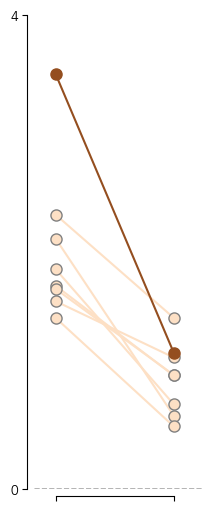

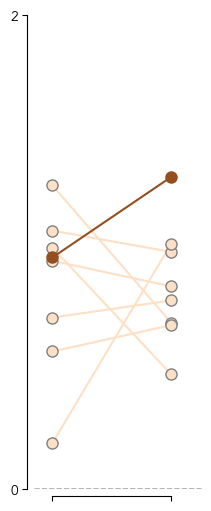

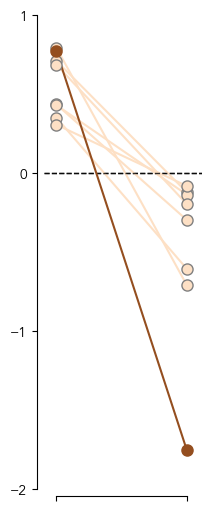

In [ ]:
savefig = False

froi_lims = {
    'FFA': [0, 4],
    'PPA': [0, 2],
    'EBA': [-2, 1],
}
froi_ticks = {
    'FFA': np.array([0, 4]),
    'PPA': np.array([0, 2]),
    'EBA': np.array([-2, -1, 0, 1]),
}

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
# x_system_offset = 0.2
# x_category_offset = 0.0425
for froi in frois:
    # froi = 'FFA'
    bag_type = froi_bags[froi]
    fig, axes = plt.subplots(1, 1, figsize=(2, 5), constrained_layout=True)
    y_lims = froi_lims[froi]
    y_ticks = froi_ticks[froi]
    for sidx, system in enumerate(['subject', model_name]):
        ax = axes
        system_responses_bag1 = []
        system_responses_bag2 = []
        color = subject_color if system == 'subject' else model_color
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            system_responses_bag1_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{system}_response']
            system_responses_bag1.append(np.median(system_responses_bag1_))
            system_responses_bag2_ = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{system}_response']
            system_responses_bag2.append(np.median(system_responses_bag2_))
        # Add a vertical line at x=0
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        if system == 'subject':
            for sbjidx, subject in enumerate(subjects):
                ax.plot(
                    [0, 1],
                    [system_responses_bag1[sbjidx], system_responses_bag2[sbjidx]],
                    '-',
                    color=subject_color,
                    alpha=1
                )
                ax.errorbar(
                    [0, 1],
                    [
                        system_responses_bag1[sbjidx],
                        system_responses_bag2[sbjidx]
                    ],
                    # xerr=[
                    #     np.std(system_responses_bag1)/np.sqrt(len(system_responses_bag1)),
                    #     np.std(system_responses_bag2)/np.sqrt(len(system_responses_bag2))
                    # ],
                    fmt='o',
                    color=subject_color,
                    alpha=1,
                    markersize=8,
                    linewidth=0,
                    zorder=4,
                    capsize=0,
                    mec='gray'
                )
        else:
            ax.plot(
                [0, 1],
                [np.median(system_responses_bag1), np.median(system_responses_bag2)],
                '-',
                color=model_color,
                alpha=1
            )
            ax.errorbar(
                [0, 1],
                [
                    np.median(system_responses_bag1),
                    np.median(system_responses_bag2)
                ],
                xerr=[
                    np.std(system_responses_bag1)/np.sqrt(len(system_responses_bag1)),
                    np.std(system_responses_bag2)/np.sqrt(len(system_responses_bag2))
                ],
                fmt='o',
                color=model_color,
                alpha=1,
                markersize=8,
                linewidth=0,
                zorder=5,
                capsize=0,
            )
        # # Add individual points
        # for i, x in zip([1, 0], [system_responses_bag1, system_responses_bag2]):
        #     ax.scatter(x, [i]*len(x), s=15, alpha=0.8, color='gray', label=f'Bag {i+1}' if sidx == 0 else "", edgecolor=None, linewidth=0.2, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        # if sidx == 1:
        #     ax.set_yticks([])  # Hide y-axis ticks for the second plot
        #     ax.set_yticklabels([])  # Hide y-axis labels for the second plot
        #     ax.spines['left'].set_visible(False)
    # plt.suptitle(f'Subject-Specific Stimuli Subset in {froi} (Model: {model_name})', y=1.02)
    # plt.tight_layout()
    if savefig:
        plt.savefig(f'{PLOTS_DIR}/fig6_lineplot_{froi}_{model_name}.pdf', dpi=300, bbox_inches='tight')
    else:
        plt.show()
    plt.close()

## g, h, i

# Supplementary

In [8]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

## Individual model deltas (+ve hypothesis)

### Stats: Linear Mixed Model

In [42]:
for model_name in TOP_MODEL_NAMES:
    print()
    print(f"Analyzing model: {model_name}")
    # model_name = 'resnet50imagenet1kv2'
    froi = 'PPA'
    bag_type = froi_bags[froi]
    bag1_label = '_'.join(bags[2][bag_type]['bag1']['label'].split())
    bag2_label = '_'.join(bags[2][bag_type]['bag2']['label'].split())

    data_df = []
    # Get a df with columns: nsd_id, subject, response, system (subject/model), category (bag1/bag2)
    for subject in subjects:
        bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
        bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
        sbj_froi_mdl_subset_resp_df =resp_df[
            (resp_df['subject'] == subject) &
            (resp_df['froi'] == froi)
        ]
        for nsd_id in bag1_nsdids:
            sbj_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ]['subject_response'].values[0]
            mdl_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ][f'{model_name}_response'].values[0]
            data_df.append({
                'nsd_id': nsd_id,
                'response': sbj_resp,
                'subject': subject,
                'system': 'subject',
                'category': bag1_label
            })
            data_df.append({
                'nsd_id': nsd_id,
                'response': mdl_resp,
                'subject': subject,
                'system': 'model',
                'category': bag1_label
            })
        for nsd_id in bag2_nsdids:
            sbj_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ]['subject_response'].values[0]
            mdl_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'] == nsd_id
            ][f'{model_name}_response'].values[0]
            data_df.append({
                'nsd_id': nsd_id,
                'response': sbj_resp,
                'subject': subject,
                'system': 'subject',
                'category': bag2_label
            })
            data_df.append({
                'nsd_id': nsd_id,
                'response': mdl_resp,
                'subject': subject,
                'system': 'model',
                'category': bag2_label
            })
    data_df = pd.DataFrame(data_df)
    data_df['system'] = pd.Categorical(data_df['system'], categories=['subject', 'model'], ordered=True)
    data_df['category'] = pd.Categorical(data_df['category'], categories=[bag1_label, bag2_label], ordered=True)
    data_df['subject'] = pd.Categorical(data_df['subject'], categories=subjects, ordered=True)
    # display(data_df)

    lmm_model = smf.mixedlm(
        "response ~ system * category + C(subject)", 
        data_df, 
        groups=data_df["subject"], 
        # re_formula="~category" # Random slopes for category within subjects
    )
    results = lmm_model.fit(method='lbfgs', reml=True, maxiter=2000, full_output=True)
    print(results.summary())

    # fe = smf.ols("response ~ system * category + C(subject)", data=data_df).fit()
    # print(fe.summary())


Analyzing model: resnet50imagenet1kv2
                            Mixed Linear Model Regression Results
Model:                          MixedLM             Dependent Variable:             response 
No. Observations:               784                 Method:                         REML     
No. Groups:                     7                   Scale:                          0.6440   
Min. group size:                104                 Log-Likelihood:                 -951.6824
Max. group size:                132                 Converged:                      Yes      
Mean group size:                112.0                                                        
---------------------------------------------------------------------------------------------
                                               Coef.    Std.Err.     z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------------------
Intercept                                       0

### Plot: Individual models

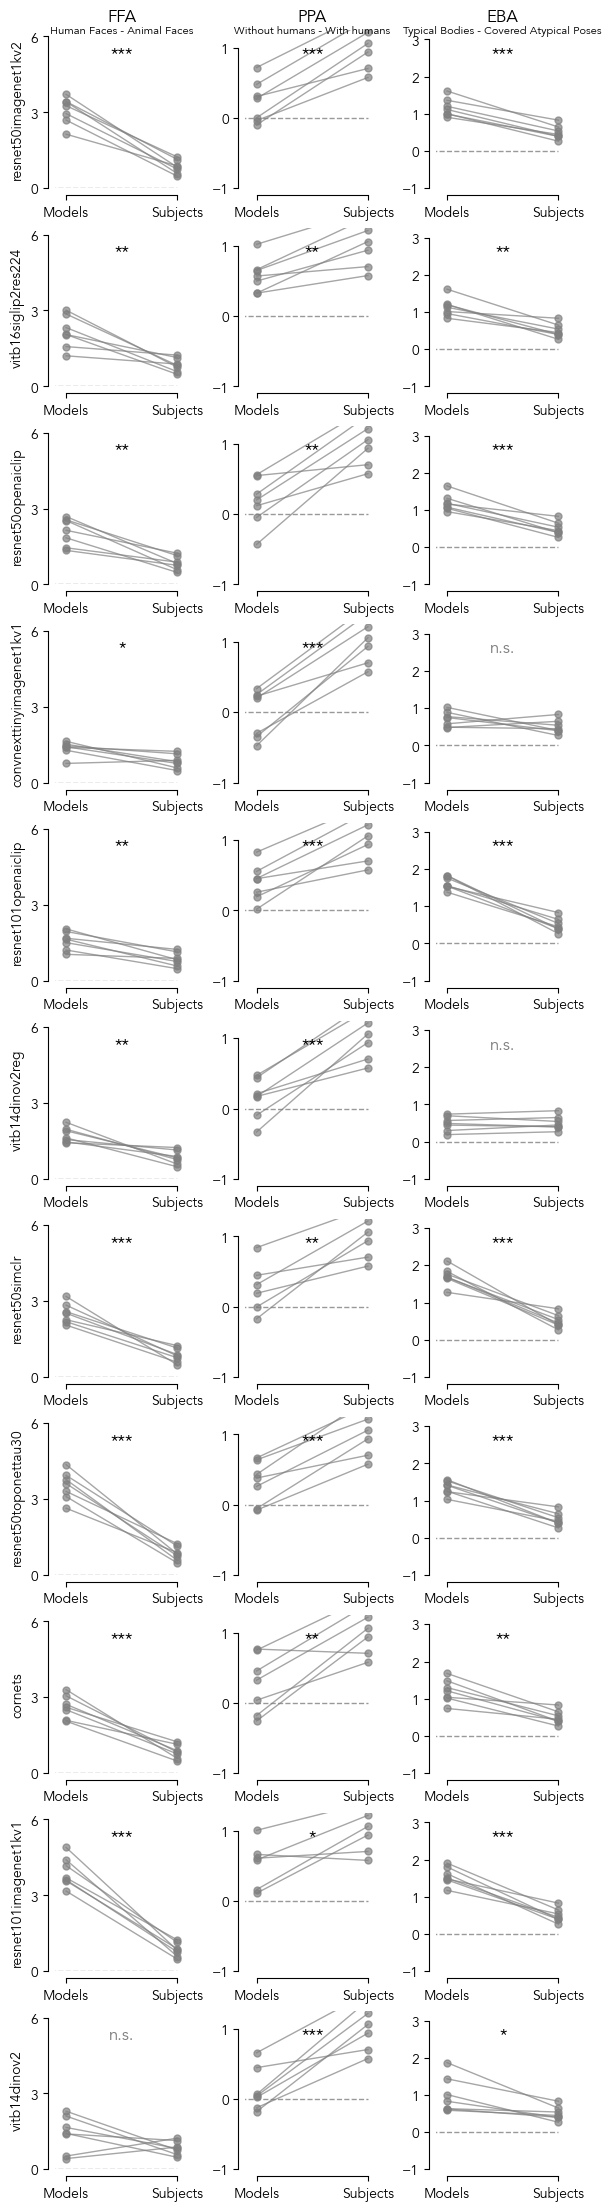

In [5]:
savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

#### EBA: Human faces vs. Animal faces

EBA, vitb16siglip2res224 model delta not normal (Shapiro p=0.0276)
PPA, resnet101openaiclip model delta not normal (Shapiro p=0.0426)
PPA, cornets model delta not normal (Shapiro p=0.0387)


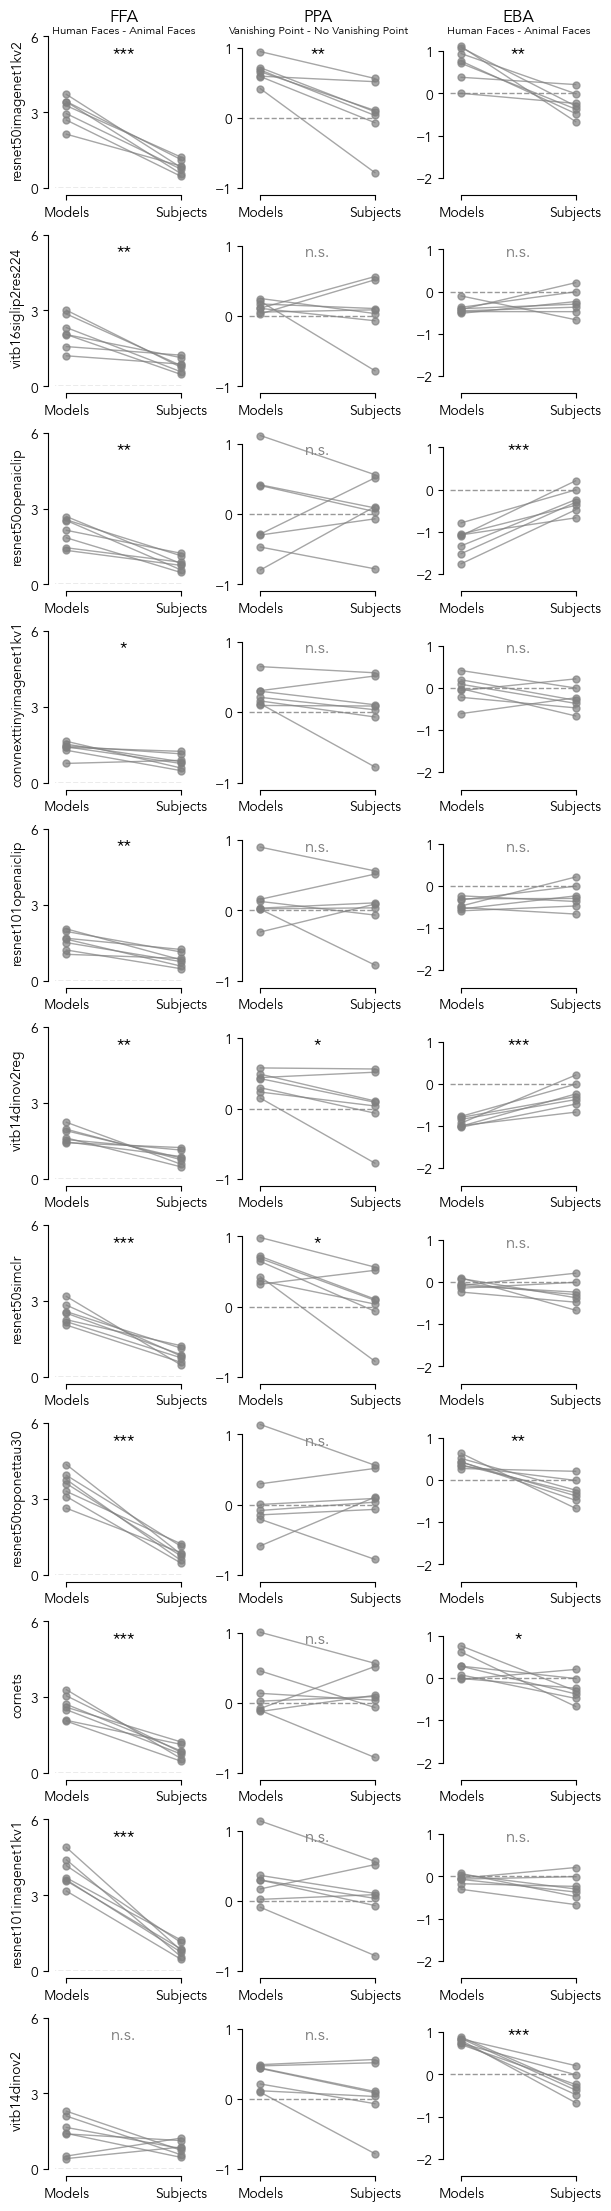

In [8]:
froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes_perspective',
    'EBA': 'faces',
}

savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-2.25, 1.5],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-2, -1, 0, 1]),
}

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Across models

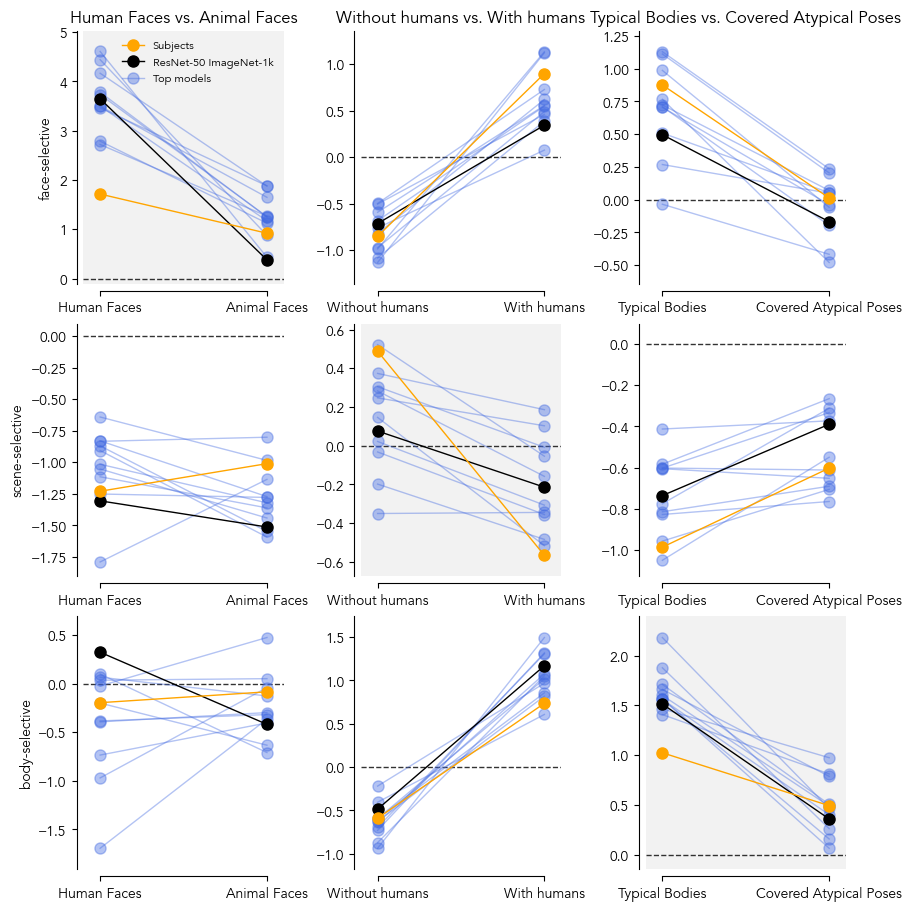

In [7]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.4,
                markersize=8,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        ax.plot([], [], '-o', color=othermodels_color, alpha=0.4, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Held-out models

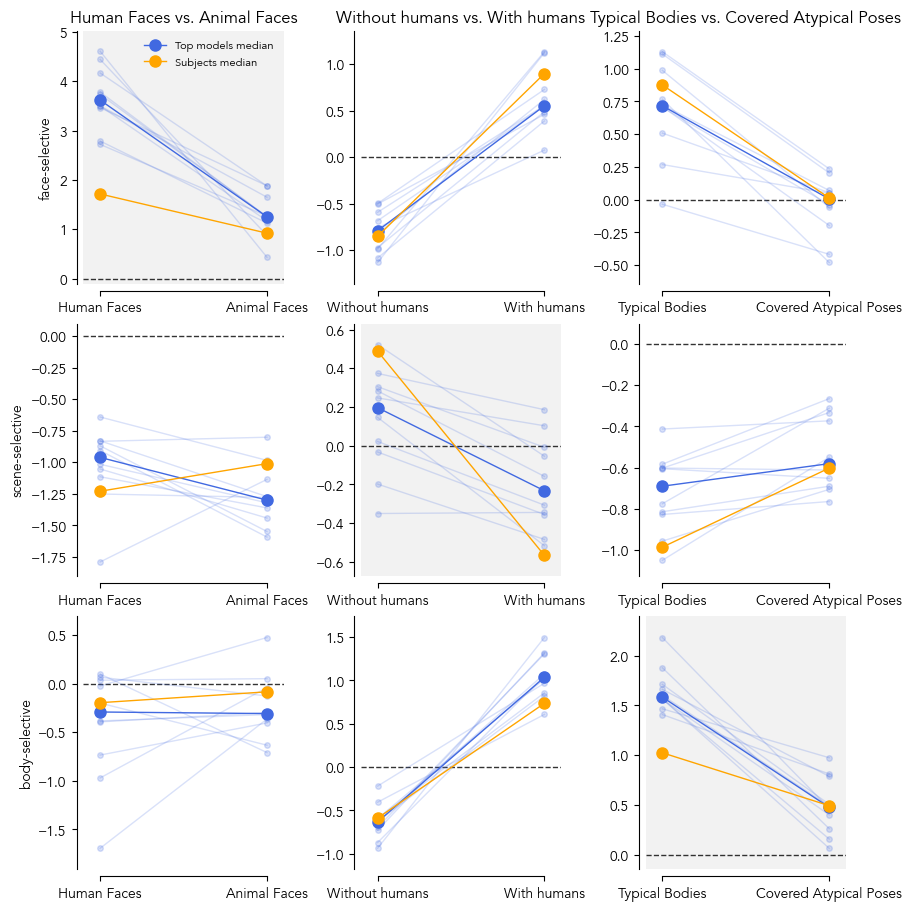

In [8]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
# rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        models_pts = []
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            models_pts.append(model_pts_medians)
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.2,
                markersize=4,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Plot median across models
        models_pts = np.array(models_pts)
        models_pts_medians = np.median(models_pts, axis=0)
        ax_pts += models_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [models_pts_medians[0], models_pts_medians[1]],
            '-o',
            color=othermodels_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Top models median' if bidx == 0 and fidx == 0 else "",
        )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects median' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        # ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        # ax.plot([], [], '-o', color=othermodels_color, alpha=1, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

### Plot: Held-out models deltas

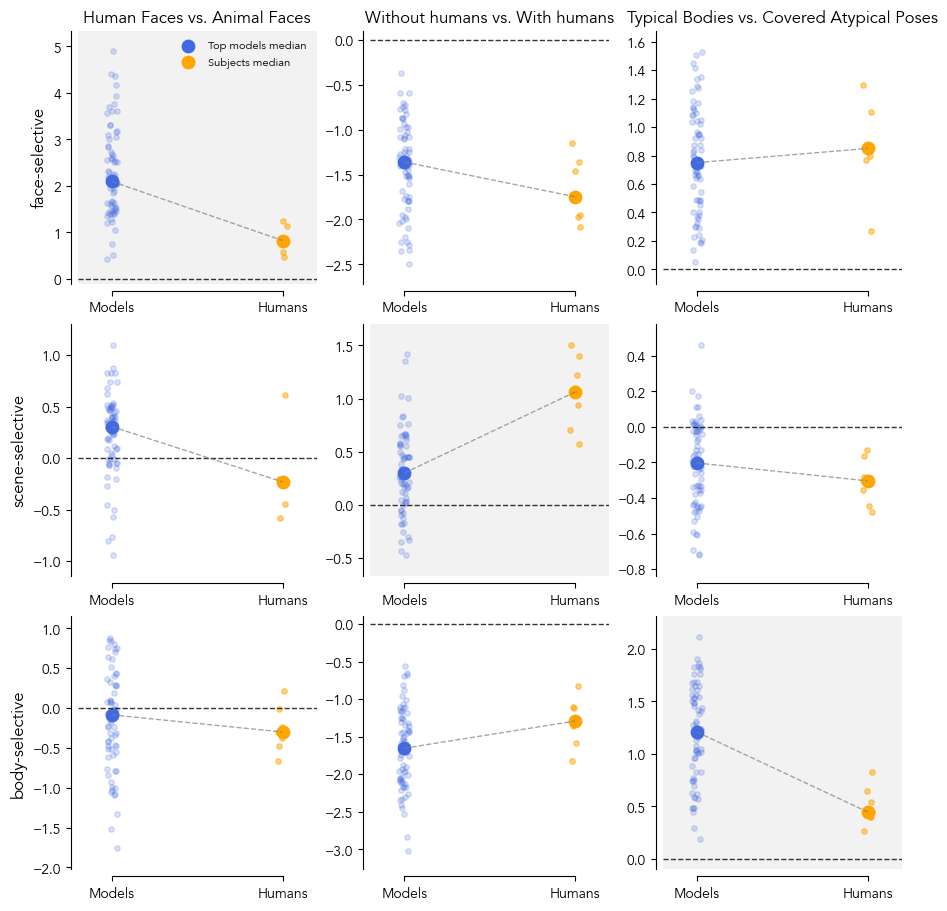

In [10]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        
        # Calculate model deltas
        model_deltas = []
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            
            model_subject_deltas = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                
                # Calculate delta between bag1 and bag2 (switched from bag2 - bag1)
                delta = model_responses_bag1_median - model_responses_bag2_median
                model_subject_deltas.append(delta)
            
            model_deltas.append(model_subject_deltas)
            
            # Plot individual model deltas with jitter
            for i, delta in enumerate(model_subject_deltas):
                jitter = np.random.uniform(-0.03, 0.03)
                ax.scatter(0 + jitter, delta, color=othermodels_color, alpha=0.2, s=15)
                ax_pts.append(delta)
        
        # Calculate median model delta
        model_deltas = np.array(model_deltas)
        model_median_delta = np.median(model_deltas)
        ax_pts.append(model_median_delta)
        
        # Plot median model delta
        ax.scatter(0, model_median_delta, color=othermodels_color, s=80, marker='o', 
                   label='Top models median' if bidx == 0 and fidx == 0 else "")
        
        # Calculate subject deltas
        subject_deltas = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            
            # Calculate delta between bag1 and bag2 (switched from bag2 - bag1)
            delta = subject_responses_bag1_median - subject_responses_bag2_median
            subject_deltas.append(delta)
            
            # Plot individual subject deltas with jitter
            jitter = np.random.uniform(-0.03, 0.03)
            ax.scatter(1 + jitter, delta, color=subjects_color, alpha=0.5, s=15)
            ax_pts.append(delta)
        
        # Calculate median subject delta
        subject_deltas = np.array(subject_deltas)
        subject_median_delta = np.median(subject_deltas)
        ax_pts.append(subject_median_delta)
        
        # Plot median subject delta
        ax.scatter(1, subject_median_delta, color=subjects_color, s=80, marker='o',
                   label='Subjects median' if bidx == 0 and fidx == 0 else "")
        
        # Connect median points with a line
        ax.plot([0, 1], [model_median_delta, subject_median_delta], '--', color='gray', alpha=0.7, linewidth=1)
        
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_range = ax_pts.max() - ax_pts.min()
        ax_min = np.min([ax_pts.min() - 0.1 * ax_range, -0.1])
        ax_max = np.max([ax_pts.max() + 0.1 * ax_range, 0.1])
        
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Humans'])
        ax.set_xlim([-0.2, 1.2])
        ax.set_ylim(ax_min, ax_max)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['bottom'].set_bounds(0, 1)
        
        # Update labels to reflect bag1 - bag2 instead of bag2 - bag1
        # \n{bag1_label} - {bag2_label}
        ax.set_ylabel(f"{froi_labels[froi]}" if bidx == 0 else "", fontsize=12)
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
            
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
            
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_delta_models_vs_humans.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

## Alternate z-scoring

In [12]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

frois = ['FFA', 'PPA', 'EBA']
subjects = [2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_responses_df_path = f'results/exploration/explore_interpret/subject_specific_mean_responses.csv'
resp_df = pd.read_csv(mean_responses_df_path)

froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes',
    'EBA': 'bodies',
}
model_color = '#944e1f' # Brown
subject_color = '#fde0c5' # Light peach

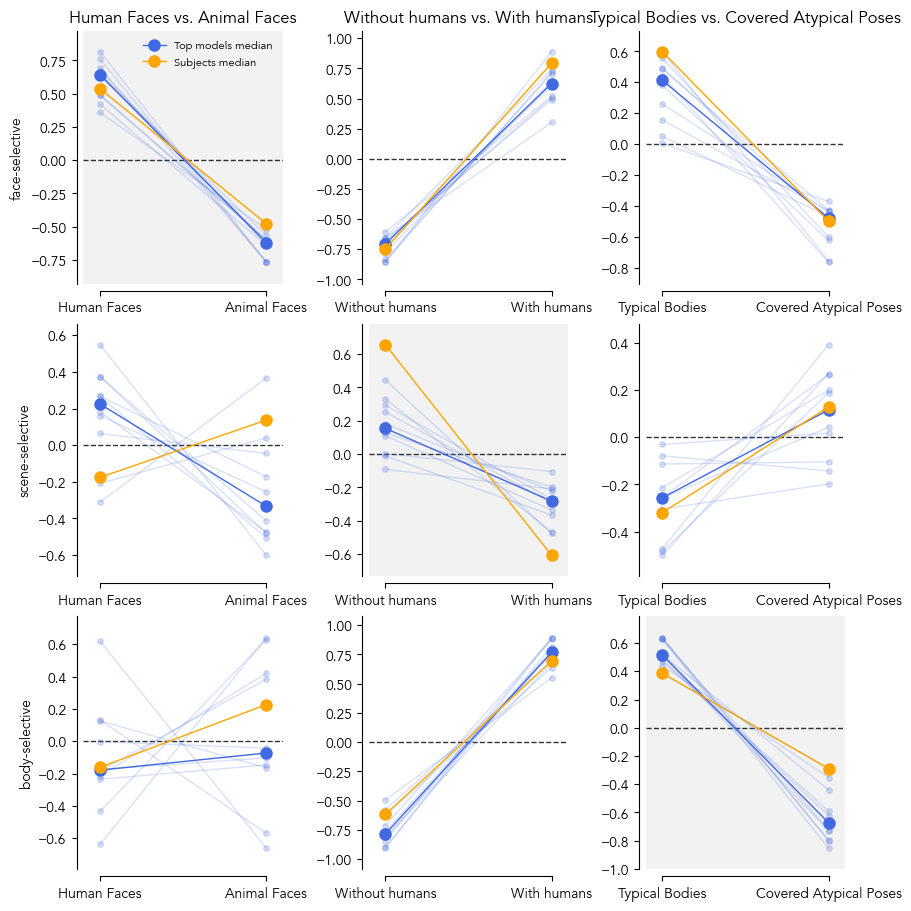

In [13]:
savefig = False

bag_types = ['faces', 'scenes', 'bodies']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
# rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        models_pts = []
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            if model_name == 'resnet50imagenet1kv2':
                continue # Skip ResNet-50 ImageNet-1k
            model_pts = []
            for subject in range(2, 9):
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                bag1_pts = np.array(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                bag2_pts = np.array(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                # Calculate combined bags mean and std for z-scoring
                combined_bags = np.concatenate([bag1_pts, bag2_pts])
                combined_mean = np.mean(combined_bags)
                combined_std = np.std(combined_bags)
                # Z-score the model responses within the combined bags
                bag1_pts_z = (bag1_pts - combined_mean) / combined_std
                bag2_pts_z = (bag2_pts - combined_mean) / combined_std
                # Calculate median of z-scored responses
                model_responses_bag1_median = np.median(bag1_pts_z)
                model_responses_bag2_median = np.median(bag2_pts_z)
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            models_pts.append(model_pts_medians)
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.2,
                markersize=4,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Plot median across models
        models_pts = np.array(models_pts)
        models_pts_medians = np.median(models_pts, axis=0)
        ax_pts += models_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [models_pts_medians[0], models_pts_medians[1]],
            '-o',
            color=othermodels_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Top models median' if bidx == 0 and fidx == 0 else "",
        )
        # Add median across subjects
        subject_pts = []
        for subject in range(2, 9):
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            bag1_pts = np.array(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            bag2_pts = np.array(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            # Calculate combined bags mean and std for z-scoring
            combined_bags = np.concatenate([bag1_pts, bag2_pts])
            combined_mean = np.mean(combined_bags)
            combined_std = np.std(combined_bags)
            # Z-score the model responses within the combined bags
            bag1_pts_z = (bag1_pts - combined_mean) / combined_std
            bag2_pts_z = (bag2_pts - combined_mean) / combined_std
            # Calculate median of z-scored responses
            subject_responses_bag1_median = np.median(bag1_pts_z)
            subject_responses_bag2_median = np.median(bag2_pts_z)
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects median' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        # ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        # ax.plot([], [], '-o', color=othermodels_color, alpha=1, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()